# Comprension_eda: análisis exploratorio de datos

**Objetivo del proyecto:** predecir si un cliente pagará a tiempo su crédito (`Pago_atiempo`).

**Objetivo de este notebook:** entender el esquema y el contenido de `Base_de_datos.csv`,
detectar problemas de calidad, caracterizar cada variable, estudiar su relación con la variable
objetivo y dejar definidos tres insumos para las etapas siguientes:

1. reglas de validación de datos (sección 7);
2. transformaciones candidatas (sección 8);
3. atributos derivados candidatos (sección 9).

**Convención de los textos:** en las interpretaciones se distingue entre *hecho* (lo que muestran
los datos), *inferencia* (lo que se deduce razonablemente) e *hipótesis* (lo que hay que
confirmar con el área de negocio o con el dueño de los datos).

## 1. Librerías y configuración

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Configuración de visualización: estilo uniforme y tablas legibles.
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
warnings.filterwarnings("ignore", category=FutureWarning)

OBJETIVO = "Pago_atiempo"

## 2. Lectura de datos

Se lee el CSV generado por `Cargar_datos.ipynb`. Se conserva una copia sin modificar (`df_raw`)
porque las reglas de validación de la sección 7 se evalúan sobre el dato **tal como llega**,
no sobre el dato ya corregido.

In [2]:
df_raw = pd.read_csv("Base_de_datos.csv")
df = df_raw.copy()
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 10,763 | Columnas: 23


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


## 3. Exploración inicial de datos

### 3.1 Descripción general

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  float64
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  float64
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

In [4]:
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")
resumen = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isna().sum(),
    "ejemplo": df.iloc[0],
})
resumen

Filas duplicadas exactas: 0


,tipo_pandas,valores_unicos,nulos,ejemplo
tipo_credito,int64,6,0,4
fecha_prestamo,str,10758,0,2025-01-07 14:40:36
capital_prestado,float64,7306,0,"1,852,560.00"
plazo_meses,int64,18,0,12
edad_cliente,int64,54,0,32
tipo_laboral,str,2,0,Empleado
salario_cliente,int64,1385,0,3500000
total_otros_prestamos,int64,1538,0,1000000
cuota_pactada,int64,9836,0,128650
puntaje,float64,248,0,95.23


**Interpretación**

- *Hecho:* 10.763 registros y 23 columnas, sin filas duplicadas. Cada fila corresponde a un
  crédito otorgado; `fecha_prestamo` tiene 10.758 valores distintos, por lo que funciona casi como
  un identificador temporal del registro.
- *Hecho:* pandas infiere 20 columnas numéricas y 3 de texto (`fecha_prestamo`, `tipo_laboral`,
  `tendencia_ingresos`). Varias inferencias no son correctas desde el punto de vista del
  negocio: `tipo_credito` es un código (categoría) y no una cantidad, `fecha_prestamo` es una
  fecha y `Pago_atiempo` es binaria. Se corrigen en la sección 3.5.
- *Hecho:* `tendencia_ingresos` tiene 46 valores distintos cuando conceptualmente debería tener
  tres (Creciente, Decreciente, Estable). Esto indica datos mal cargados en esa columna (3.5).

### 3.2 Diccionario de datos y caracterización de variables

La descripción de cada variable es una *inferencia* a partir del nombre y del contenido; debe
confirmarse con el dueño de los datos. La clasificación sigue la taxonomía pedida:

- **Numérica** continua o discreta.
- **Categórica** nominal (sin orden) u ordinal (con orden); dicotómica (2 niveles) o politómica (más de 2).

In [5]:
diccionario = pd.DataFrame([
    ("tipo_credito", "Código del producto de crédito", "Categórica", "Nominal, politómica", "category"),
    ("fecha_prestamo", "Fecha y hora de desembolso", "Fecha", "Temporal", "datetime64"),
    ("capital_prestado", "Monto desembolsado (COP)", "Numérica", "Continua", "float64"),
    ("plazo_meses", "Plazo pactado en meses", "Numérica", "Discreta", "int64"),
    ("edad_cliente", "Edad del cliente en años", "Numérica", "Discreta", "int64"),
    ("tipo_laboral", "Empleado o independiente", "Categórica", "Nominal, dicotómica", "category"),
    ("salario_cliente", "Ingreso mensual declarado (COP)", "Numérica", "Continua", "float64"),
    ("total_otros_prestamos", "Monto de otros préstamos del cliente (COP)", "Numérica", "Continua", "float64"),
    ("cuota_pactada", "Cuota mensual del crédito (COP)", "Numérica", "Continua", "float64"),
    ("puntaje", "Puntaje interno del cliente", "Numérica", "Continua", "float64"),
    ("puntaje_datacredito", "Puntaje de la central de riesgo", "Numérica", "Discreta (escala de puntaje)", "float64"),
    ("cant_creditosvigentes", "Número de créditos vigentes", "Numérica", "Discreta (conteo)", "int64"),
    ("huella_consulta", "Número de consultas recientes en la central", "Numérica", "Discreta (conteo)", "int64"),
    ("saldo_mora", "Saldo en mora reportado (COP)", "Numérica", "Continua", "float64"),
    ("saldo_total", "Saldo total de deudas reportado (COP)", "Numérica", "Continua", "float64"),
    ("saldo_principal", "Saldo de capital reportado (COP)", "Numérica", "Continua", "float64"),
    ("saldo_mora_codeudor", "Saldo en mora como codeudor (COP)", "Numérica", "Continua", "float64"),
    ("creditos_sectorFinanciero", "Créditos con el sector financiero", "Numérica", "Discreta (conteo)", "int64"),
    ("creditos_sectorCooperativo", "Créditos con el sector cooperativo", "Numérica", "Discreta (conteo)", "int64"),
    ("creditos_sectorReal", "Créditos con el sector real", "Numérica", "Discreta (conteo)", "int64"),
    ("promedio_ingresos_datacredito", "Ingreso promedio estimado por la central (COP)", "Numérica", "Continua", "float64"),
    ("tendencia_ingresos", "Tendencia del ingreso", "Categórica", "Ordinal, politómica", "category"),
    ("Pago_atiempo", "Variable objetivo: 1 pagó a tiempo, 0 no", "Categórica", "Nominal, dicotómica", "int (0/1)"),
], columns=["variable", "descripcion", "tipo", "subtipo", "tipo_destino"])
diccionario

,variable,descripcion,tipo,subtipo,tipo_destino
0,tipo_credito,Código del producto de crédito,Categórica,"Nominal, politómica",category
1,fecha_prestamo,Fecha y hora de desembolso,Fecha,Temporal,datetime64
2,capital_prestado,Monto desembolsado (COP),Numérica,Continua,float64
3,plazo_meses,Plazo pactado en meses,Numérica,Discreta,int64
4,edad_cliente,Edad del cliente en años,Numérica,Discreta,int64
5,tipo_laboral,Empleado o independiente,Categórica,"Nominal, dicotómica",category
6,salario_cliente,Ingreso mensual declarado (COP),Numérica,Continua,float64
7,total_otros_prestamos,Monto de otros préstamos del cliente (COP),Numérica,Continua,float64
8,cuota_pactada,Cuota mensual del crédito (COP),Numérica,Continua,float64
9,puntaje,Puntaje interno del cliente,Numérica,Continua,float64


In [6]:
# Resumen de la caracterización: cuántas variables hay de cada clase.
diccionario.groupby(["tipo", "subtipo"]).size().rename("n_variables").to_frame()

n_variables
tipo       subtipo                                  
Categórica Nominal, dicotómica                     2
           Nominal, politómica                     1
           Ordinal, politómica                     1
Fecha      Temporal                                1
Numérica   Continua                               10
           Discreta                                2
           Discreta (conteo)                       5
           Discreta (escala de puntaje)            1

**Interpretación**

- El dataset es mayoritariamente numérico (18 variables), con 4 categóricas y 1 fecha.
- `tendencia_ingresos` se trata como **ordinal** (Decreciente < Estable < Creciente), lo que
  permite codificarla con un orden en lugar de usar one-hot.
- `tipo_credito` viene como número pero es **nominal**: el código 9 no es "más" que el 4. Usarlo
  como numérico en un modelo lineal introduciría un orden falso.
- Las variables de conteo (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`) son
  discretas y no negativas; las monetarias son continuas y no negativas.

### 3.3 Revisión de nulos y unificación de su representación

Antes de contar nulos hay que asegurarse de que todos se representen igual. Se buscan
representaciones alternativas habituales (`"None"`, `"NULL"`, `"N/A"`, `"nan"`, `""`, `"-"`)
en las columnas de texto y se reemplazan por `NaN`.

In [7]:
MARCADORES_NULO = ["None", "NULL", "null", "N/A", "NA", "nan", "NaN", "", " ", "-"]
cols_texto = df.select_dtypes(include=["object", "string"]).columns

# Cuántas celdas usan cada marcador alternativo, para documentar si el reemplazo hace algo.
marcadores_encontrados = {
    col: int(df[col].astype(str).str.strip().isin(MARCADORES_NULO).sum()) for col in cols_texto
}
print("Celdas con marcadores alternativos de nulo:", marcadores_encontrados)

df[cols_texto] = df[cols_texto].replace(MARCADORES_NULO, np.nan)

Celdas con marcadores alternativos de nulo: {'fecha_prestamo': 0, 'tipo_laboral': 0, 'tendencia_ingresos': 0}


In [8]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": df.isna().mean().mul(100).round(2),
}).query("nulos > 0").sort_values("nulos", ascending=False)
nulos

,nulos,porcentaje
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


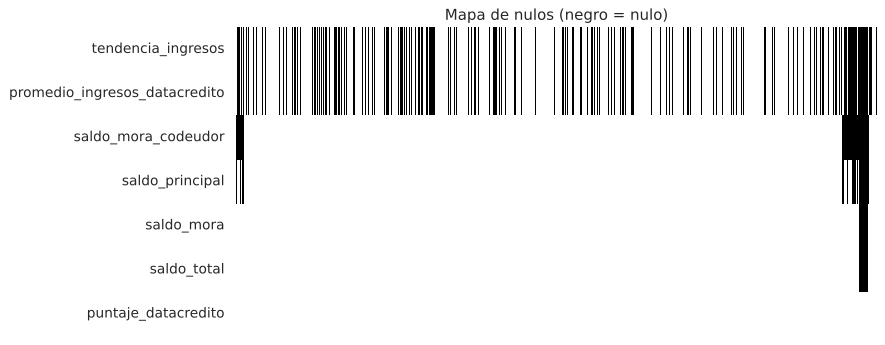

Filas con promedio_ingresos_datacredito y tendencia_ingresos nulos a la vez: 2930
Filas con saldo_mora y saldo_total nulos a la vez: 156


In [9]:
# Patrón conjunto de nulos: las columnas que vienen de la misma fuente suelen faltar juntas.
fig, ax = plt.subplots(figsize=(10, 4))
cols_con_nulos = nulos.index.tolist()
sns.heatmap(df[cols_con_nulos].isna().T, cbar=False, ax=ax, cmap="Greys", yticklabels=True)
ax.set_xticks([])
ax.set_title("Mapa de nulos (negro = nulo)")
plt.tight_layout()
plt.show()

ambos = (df["promedio_ingresos_datacredito"].isna() & df["tendencia_ingresos"].isna()).sum()
print(f"Filas con promedio_ingresos_datacredito y tendencia_ingresos nulos a la vez: {ambos}")
saldos = (df["saldo_mora"].isna() & df["saldo_total"].isna()).sum()
print(f"Filas con saldo_mora y saldo_total nulos a la vez: {saldos}")

In [10]:
# Proporción de nulos según la variable objetivo: si difiere, el nulo es informativo.
(df[cols_con_nulos].isna().groupby(df[OBJETIVO]).mean() * 100).T.round(2).rename(
    columns={0: "% nulos (no pagó)", 1: "% nulos (pagó)"})

Pago_atiempo,% nulos (no pagó),% nulos (pagó)
tendencia_ingresos,32.88,26.96
promedio_ingresos_datacredito,32.88,26.94
saldo_mora_codeudor,7.83,5.36
saldo_principal,5.68,3.67
saldo_mora,2.15,1.41
saldo_total,2.15,1.41
puntaje_datacredito,0.20,0.05


**Interpretación**

- *Hecho:* no hay representaciones alternativas de nulo en las columnas de texto; los nulos ya
  vienen como celdas vacías y pandas los lee como `NaN`. El reemplazo se mantiene como medida
  defensiva y se convertirá en regla de validación.
- *Hecho:* 7 columnas tienen nulos. Las dos más afectadas (`promedio_ingresos_datacredito` y
  `tendencia_ingresos`, cerca del 27 %) faltan **juntas** en 2.930 filas, y `saldo_mora` y
  `saldo_total` faltan juntas en las 156 filas.
- *Inferencia:* los nulos no son aleatorios, sino que dependen de la fuente: si la central de riesgo
  no devuelve información de ingresos, faltan ambas columnas. Hay 2 filas con `tendencia_ingresos` nula pero
  `promedio_ingresos_datacredito` informado; se controlan con la regla R18 (sección 7).
- *Hecho:* los nulos de ingresos son más frecuentes entre quienes no pagan (cerca de 33 % frente
  a 27 %). *Inferencia:* la ausencia de información es en sí misma una señal; conviene crear un
  indicador de nulo en lugar de solo imputar (sección 9).
- *Hecho:* también hay nulos "disfrazados" en columnas numéricas (valores 0 o fuera de rango que
  representan ausencia de dato). Se tratan en 3.5.

### 3.4 Eliminación de variables irrelevantes

Se consideran irrelevantes las variables que no aportan información (constantes o casi
constantes), los identificadores y las que no estarían disponibles en el momento de la
predicción o que filtran el resultado (fuga de información, *data leakage*).

In [11]:
# Proporción del valor más frecuente (incluido el nulo): cerca de 100 % indica una variable casi constante.
dominancia = (df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
                .mul(100).round(2).sort_values(ascending=False).rename("% valor_mas_frecuente"))
dominancia.head(6).to_frame()

,% valor_mas_frecuente
saldo_mora,98.04
Pago_atiempo,95.25
saldo_mora_codeudor,94.49
puntaje,87.40
creditos_sectorCooperativo,82.39
tipo_credito,71.98


In [12]:
print(df["saldo_mora_codeudor"].value_counts(dropna=False))

saldo_mora_codeudor
0.00        10170
NaN           590
30.00           1
470.00          1
2,145.00        1
Name: count, dtype: int64


In [13]:
# Variable puntaje: se compara su distribución según el objetivo.
puntaje_max = df["puntaje"].max()
pd.crosstab(np.isclose(df["puntaje"], puntaje_max), df[OBJETIVO],
            rownames=[f"puntaje == {puntaje_max:.2f}"], colnames=[OBJETIVO], margins=True)

Pago_atiempo,0,1,All
puntaje == 95.23,,,
False,511,845,1356
True,0,9407,9407
All,511,10252,10763


**Decisiones**

| Variable | Decisión | Motivo |
|---|---|---|
| `saldo_mora_codeudor` | Se elimina | *Hecho:* 10.170 ceros, 590 nulos y solo 3 valores distintos de cero. No tiene variabilidad suficiente para aportar al modelo. |
| `puntaje` | Se conserva en el EDA y se **excluye del modelo** hasta validarla | *Hecho:* los 9.407 registros con el puntaje máximo (95,23) pagaron a tiempo, y los 511 que no pagaron tienen un puntaje inferior. Su correlación con el objetivo es 0,92. *Hipótesis:* el puntaje se calcula o actualiza **después** de conocer el comportamiento de pago, lo que sería fuga de información. Hay que confirmar con negocio en qué momento se calcula. |
| `fecha_prestamo` | Se conserva solo para derivar atributos | Como valor crudo es casi un identificador (10.758 valores únicos) y no generaliza; sirve para extraer mes, día de la semana o antigüedad y para hacer particiones temporales. |

No hay columnas de identificador (ID de cliente o de crédito) que eliminar.

In [14]:
VARIABLES_ELIMINADAS = ["saldo_mora_codeudor"]
VARIABLES_EXCLUIR_MODELO = ["puntaje"]  # sospecha de fuga de información; validar con negocio

df = df.drop(columns=VARIABLES_ELIMINADAS)
print(f"Columnas restantes: {df.shape[1]}")

Columnas restantes: 22


### 3.5 Conversión de tipos y corrección de datos

Cada columna debe tener un tipo uniforme. Primero se revisan los valores incoherentes y luego se
asignan los tipos definitivos.

**a) `tendencia_ingresos` mezcla categorías y números**

In [15]:
CATEGORIAS_TENDENCIA = ["Decreciente", "Estable", "Creciente"]
tendencia_invalida = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(CATEGORIAS_TENDENCIA)
print(f"Registros con valor no válido en tendencia_ingresos: {tendencia_invalida.sum()}")
df.loc[tendencia_invalida, ["promedio_ingresos_datacredito", "tendencia_ingresos", "salario_cliente"]].head(8)

Registros con valor no válido en tendencia_ingresos: 58


,promedio_ingresos_datacredito,tendencia_ingresos,salario_cliente
64,"881,581.00",8315,3000000
152,"939,017.00",8315,4000000
163,"1,200,000.00",0,5000000
426,"28,878,675.00",158042,44707750
468,"1,562,215.00",3978,6000000
671,"1,000,000.00",9147,3100000
1129,"977,131.00",8315,2990000
1132,"2,550,000.00",168750,2900000


*Hecho:* 58 registros tienen números (positivos, negativos y cero) en lugar de una categoría.
*Inferencia:* parece una variación de ingreso en pesos que se cargó en la columna de la categoría.
No hay una regla fiable para traducir esos montos a categoría, así que se reemplazan por `NaN` y
se tratarán como el resto de nulos de la variable.

**b) Valores imposibles o centinela en variables numéricas**

In [16]:
print("edad_cliente > 100:", (df["edad_cliente"] > 100).sum(),
      "| valores:", sorted(df.loc[df["edad_cliente"] > 100, "edad_cliente"].unique()))
print("puntaje_datacredito < 100:", (df["puntaje_datacredito"] < 100).sum(),
      "| valores:", sorted(df.loc[df["puntaje_datacredito"] < 100, "puntaje_datacredito"].unique()))
print("Siguiente valor más bajo:", df.loc[df["puntaje_datacredito"] >= 100, "puntaje_datacredito"].min())
print("salario_cliente == 0:", (df["salario_cliente"] == 0).sum())
print("salario_cliente > 100 millones:", (df["salario_cliente"] > 1e8).sum())
print("tipo_credito poco frecuentes:", df["tipo_credito"].value_counts().loc[lambda s: s < 30].to_dict())

edad_cliente > 100: 150 | valores: [np.int64(121), np.int64(122), np.int64(123)]
puntaje_datacredito < 100: 147 | valores: [np.float64(-7.0), np.float64(0.0), np.float64(7.0)]
Siguiente valor más bajo: 287.0
salario_cliente == 0: 24
salario_cliente > 100 millones: 74
tipo_credito poco frecuentes: {6: 21, 7: 2, 68: 1}


- *Hecho:* 150 clientes tienen entre 121 y 123 años, una edad no plausible para un solicitante.
  Sin ellos, la edad máxima es 69 años: no hay valores intermedios entre 69 y 121, lo que sugiere
  un valor por defecto del sistema de origen. Se convierten a `NaN`.
- *Hecho:* 147 registros tienen `puntaje_datacredito` por debajo de 100 (145 con 0, uno con -7 y
  uno con 7); el siguiente valor es 287 y el percentil 5 es 710. *Inferencia:* un puntaje de
  central no puede ser negativo, y 0 o 7 están completamente separados del resto; lo más probable
  es que indiquen "sin puntaje". Se convierten a `NaN`. Los valores entre 287 y 600 son pocos pero
  plausibles, y se conservan.
- *Hecho:* 24 clientes declaran salario 0 y 74 declaran más de 100 millones mensuales (máximo
  22.000 millones). No se corrigen en el EDA porque no hay forma de saber el valor real; se
  documentan como reglas de validación (sección 7) y como candidatos a tratamiento de atípicos
  (sección 8).
- *Hecho:* `tipo_credito` tiene códigos con muy pocos registros (68 y 7). Se mantienen, pero se
  propone agruparlos en "Otros" al codificar.

In [17]:
# Correcciones: los valores no válidos pasan a nulo para que se traten de forma uniforme.
df.loc[tendencia_invalida, "tendencia_ingresos"] = np.nan
df.loc[df["edad_cliente"] > 100, "edad_cliente"] = np.nan
df.loc[df["puntaje_datacredito"] < 100, "puntaje_datacredito"] = np.nan

# Tipos definitivos.
df["fecha_prestamo"] = pd.to_datetime(df["fecha_prestamo"], format="%Y-%m-%d %H:%M:%S")
df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")
df["tendencia_ingresos"] = pd.Categorical(df["tendencia_ingresos"], categories=CATEGORIAS_TENDENCIA, ordered=True)
df[OBJETIVO] = df[OBJETIVO].astype("int8")

# Montos en float para que todas las columnas monetarias tengan el mismo tipo.
COLS_MONETARIAS = ["capital_prestado", "salario_cliente", "total_otros_prestamos", "cuota_pactada",
                   "saldo_mora", "saldo_total", "saldo_principal", "promedio_ingresos_datacredito"]
df[COLS_MONETARIAS] = df[COLS_MONETARIAS].astype("float64")

df.dtypes.to_frame("tipo_final")

,tipo_final
tipo_credito,category
fecha_prestamo,datetime64[us]
capital_prestado,float64
plazo_meses,int64
edad_cliente,float64
tipo_laboral,category
salario_cliente,float64
total_otros_prestamos,float64
cuota_pactada,float64
puntaje,float64


In [18]:
# Listas de trabajo que se usan en el resto del notebook.
COLS_CATEGORICAS = ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]
COLS_NUMERICAS = [col for col in df.select_dtypes(include="number").columns if col != OBJETIVO]
print("Numéricas:", len(COLS_NUMERICAS), "| Categóricas:", len(COLS_CATEGORICAS))

Numéricas: 17 | Categóricas: 3


## 4. Análisis univariable

### 4.1 `describe()` con los tipos ya ajustados

In [19]:
df[COLS_NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00
salario_cliente,"10,763.00","17,216,431.46","355,476,717.60",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,610.00",791.61,50.87,287.00,758.00,792.00,826.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00


In [20]:
df[COLS_CATEGORICAS + ["fecha_prestamo"]].describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max
tipo_credito,"10,763.00",6.00,4.00,"7,747.00",NaN,NaN,NaN,NaN,NaN,NaN
tipo_laboral,10763,2,Empleado,6754,NaN,NaN,NaN,NaN,NaN,NaN
tendencia_ingresos,7773,3,Creciente,5294,NaN,NaN,NaN,NaN,NaN,NaN
fecha_prestamo,10763,NaN,NaN,NaN,2025-04-16 23:06:02.111121,2024-11-26 09:17:04,2025-01-20 17:33:07.500000,2025-03-27 16:23:12,2025-06-16 13:27:58,2026-04-26 18:43:52


### 4.2 Descripción estadística de las variables numéricas

Se calculan tendencia central (media, mediana, moda), posición (mínimo, cuartiles, máximo) y
dispersión (rango, IQR, varianza, desviación estándar, coeficiente de variación, asimetría y
curtosis). También se calcula el porcentaje de atípicos con la regla de Tukey (fuera de
Q1 - 1,5 IQR y Q3 + 1,5 IQR).

In [21]:
def resumen_estadistico(serie: pd.Series) -> pd.Series:
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    atipicos = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    return pd.Series({
        "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "min": s.min(), "Q1": q1, "Q3": q3, "max": s.max(),
        "rango": s.max() - s.min(), "IQR": iqr, "varianza": s.var(), "desv_std": s.std(),
        "coef_var": s.std() / s.mean() if s.mean() != 0 else np.nan,
        "asimetria": s.skew(), "curtosis": s.kurt(), "%_atipicos_IQR": atipicos,
    })

tabla_estadistica = df[COLS_NUMERICAS].apply(resumen_estadistico).T
with pd.option_context("display.float_format", lambda v: f"{v:,.2f}"):
    display(tabla_estadistica)

,media,mediana,moda,min,Q1,Q3,max,rango,IQR,varianza,desv_std,coef_var,asimetria,curtosis,%_atipicos_IQR
capital_prestado,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","1,224,831.00","3,084,840.00","41,444,152.80","41,084,152.80","1,860,009.00","3,646,735,466,988.66","1,909,642.76",0.78,3.72,35.32,5.11
plazo_meses,10.58,10.00,6.00,2.00,6.00,12.00,90.00,88.00,6.00,43.98,6.63,0.63,2.46,7.78,8.07
edad_cliente,42.85,42.00,40.00,19.00,33.00,52.00,69.00,50.00,19.00,142.74,11.95,0.28,0.27,-0.86,0.00
salario_cliente,"17,216,431.46","3,000,000.00","3,000,000.00",0.00,"2,000,000.00","4,875,808.00","22,000,000,000.00","22,000,000,000.00","2,875,808.00","126,363,696,758,146,032.00","355,476,717.60",20.65,43.78,"2,211.23",6.67
total_otros_prestamos,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"500,000.00","2,000,000.00","6,787,675,263.00","6,787,675,263.00","1,500,000.00","14,022,897,787,155,472.00","118,418,316.94",18.98,38.46,"1,719.28",5.47
cuota_pactada,"243,617.41","182,863.00","205,990.00","23,944.00","121,041.50","287,833.50","3,816,752.00","3,792,808.00","166,792.00","44,307,595,469.58","210,493.69",0.86,3.79,26.65,7.11
puntaje,91.17,95.23,95.23,-38.01,95.23,95.23,95.23,133.24,0.00,271.11,16.47,0.18,-4.87,24.08,12.60
puntaje_datacredito,791.61,792.00,783.00,287.00,758.00,826.00,999.00,712.00,68.00,"2,587.58",50.87,0.06,-0.69,5.23,0.46
cant_creditosvigentes,5.73,5.00,4.00,0.00,3.00,8.00,62.00,62.00,5.00,15.82,3.98,0.69,1.80,8.62,2.25
huella_consulta,4.23,4.00,2.00,0.00,2.00,6.00,29.00,29.00,4.00,9.39,3.06,0.72,1.49,4.00,2.01


**Interpretación**

- *Hecho:* en casi todas las variables monetarias la media es mucho mayor que la mediana
  (por ejemplo, `salario_cliente`: media cercana a 17 millones frente a mediana de 3 millones).
  Esto indica distribuciones muy sesgadas a la derecha, arrastradas por pocos valores extremos.
  Para describirlas es mejor usar la mediana y el IQR.
- *Hecho:* `salario_cliente`, `total_otros_prestamos`, `saldo_mora` y `saldo_total` tienen
  asimetrías mayores que 20 y curtosis de cientos o miles: colas extremadamente pesadas. Sin
  tratamiento, estos valores dominarían cualquier modelo sensible a la escala.
- *Hecho:* `saldo_mora` tiene mediana, Q1 y Q3 iguales a 0: la gran mayoría de los clientes no
  tiene mora reportada, y los pocos casos distintos de cero aparecen como atípicos. Es más útil
  como indicador binario "tiene mora" que como monto.
- *Hecho:* `puntaje` tiene la moda igual al máximo (95,23) y asimetría negativa: casi todos los
  clientes están en el tope de la escala.
- *Hecho:* `plazo_meses` tiene la moda en 6 y valores concentrados en plazos "redondos"
  (6, 10, 12, 24, 36), lo que es coherente con una oferta de productos con plazos fijos.
- *Hecho:* `edad_cliente`, ya sin los valores centinela, es aproximadamente simétrica (asimetría
  cercana a 0,3) y va de 19 a 69 años.

### 4.3 Histogramas y diagramas de caja

Para cada variable numérica se muestra el histograma (forma de la distribución) y el diagrama
de caja (mediana, IQR y atípicos).

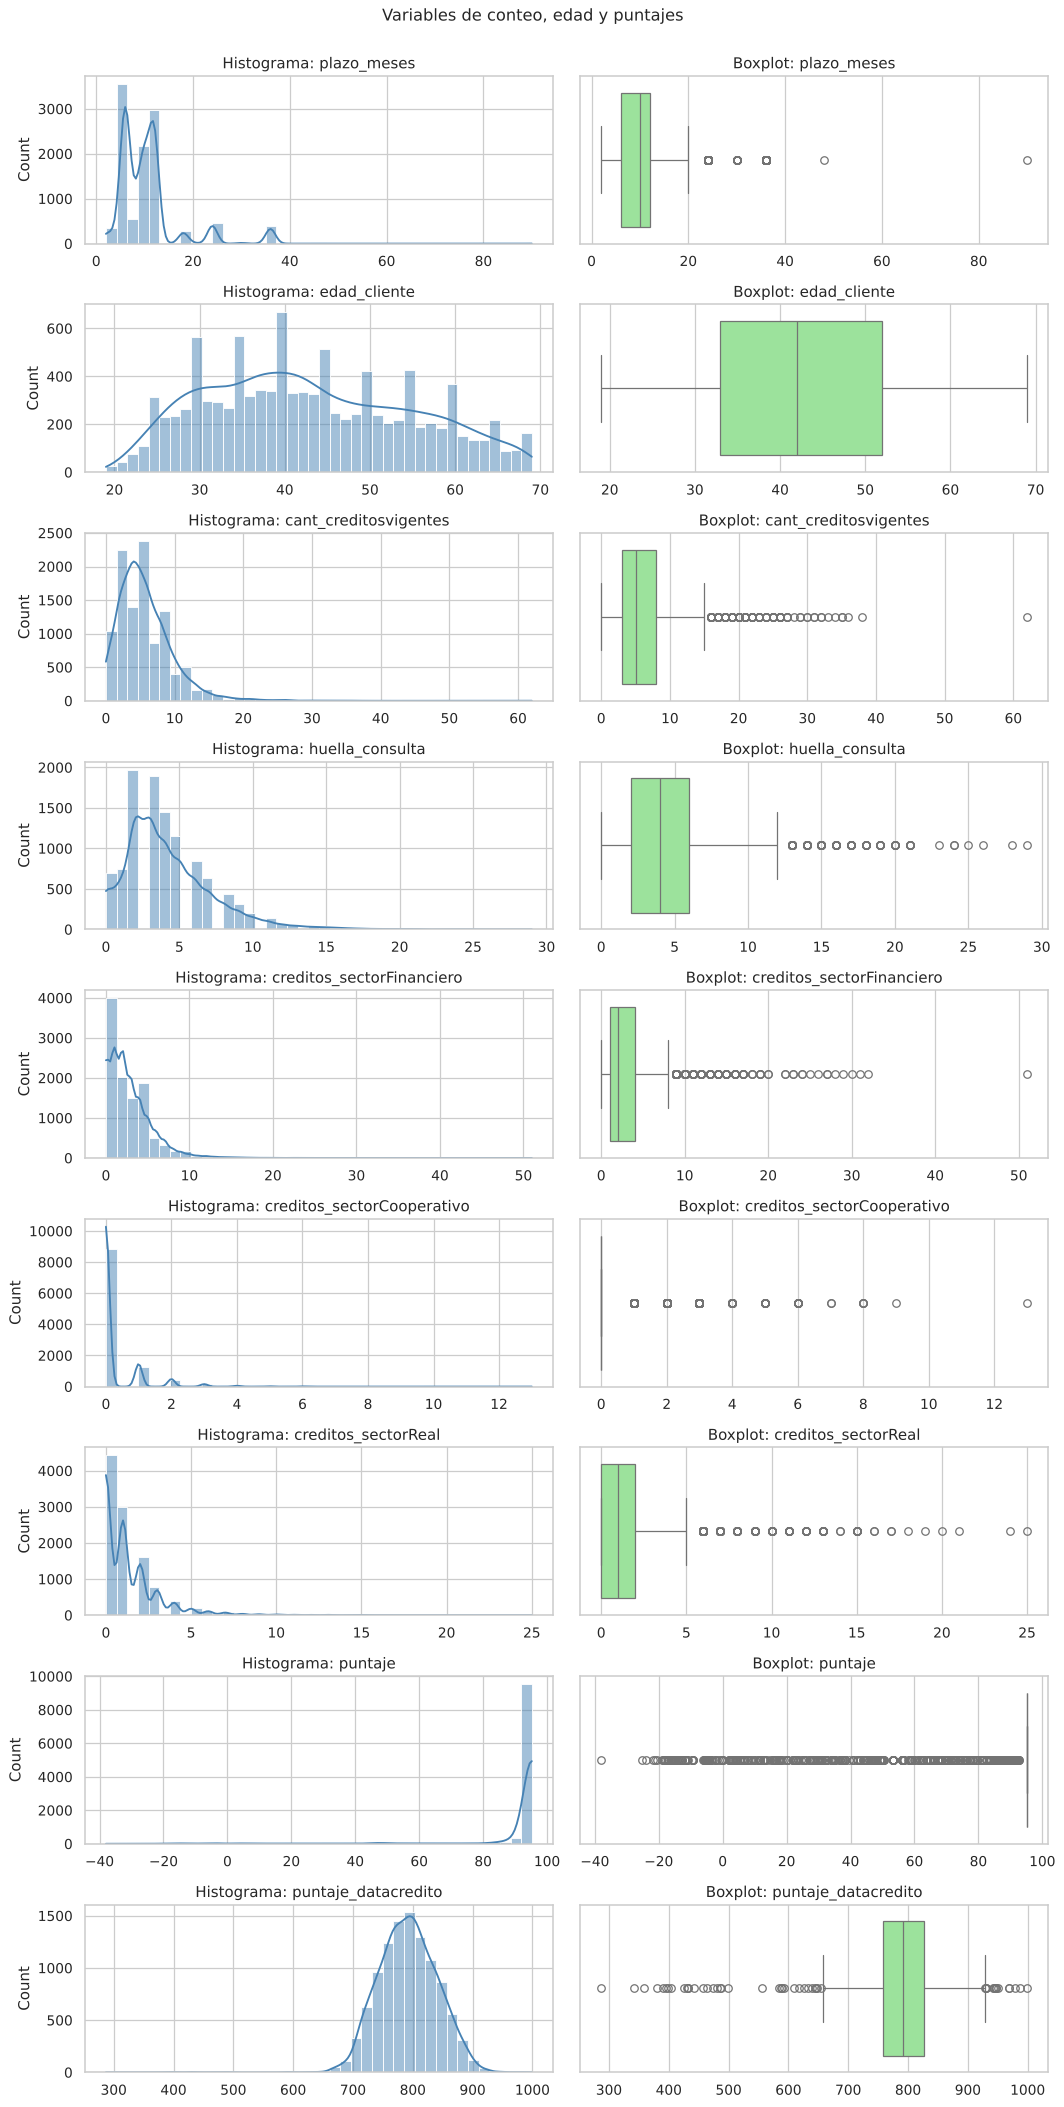

In [22]:
def graficar_distribuciones(datos, columnas, titulo, log=False):
    n = len(columnas)
    fig, axes = plt.subplots(n, 2, figsize=(12, 2.6 * n))
    for i, col in enumerate(columnas):
        s = datos[col].dropna()
        if log:
            s = np.log1p(s.clip(lower=0))
        sns.histplot(s, bins=40, kde=True, ax=axes[i, 0], color="steelblue")
        axes[i, 0].set_title(f"Histograma: {col}" + (" (log1p)" if log else ""))
        axes[i, 0].set_xlabel("")
        sns.boxplot(x=s, ax=axes[i, 1], color="lightgreen")
        axes[i, 1].set_title(f"Boxplot: {col}" + (" (log1p)" if log else ""))
        axes[i, 1].set_xlabel("")
    fig.suptitle(titulo, y=1.0, fontsize=13)
    plt.tight_layout()
    plt.show()

COLS_CONTEO = ["plazo_meses", "edad_cliente", "cant_creditosvigentes", "huella_consulta",
               "creditos_sectorFinanciero", "creditos_sectorCooperativo", "creditos_sectorReal"]
COLS_PUNTAJE = ["puntaje", "puntaje_datacredito"]

graficar_distribuciones(df, COLS_CONTEO + COLS_PUNTAJE, "Variables de conteo, edad y puntajes")

**Interpretación**

- `plazo_meses` es multimodal: picos en 6 y 12 meses y valores aislados en 48 y 90 (un registro
  cada uno), que son atípicos de negocio y deben validarse.
- `edad_cliente` se concentra entre 33 y 52 años (IQR) y llega hasta 69.
- Las variables de conteo (`cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`) tienen
  la forma típica de un conteo: muchos valores bajos y una cola larga. `creditos_sectorCooperativo`
  es 0 en la mayoría de los casos.
- `puntaje_datacredito`, una vez retirados los valores no válidos, se concentra alrededor de 790,
  con una cola corta hacia valores bajos (287 a 600) y algunos valores altos (969 a 999) que deben
  compararse con el rango oficial de la escala.
- `puntaje` está concentrado en el máximo con una cola larga hacia valores bajos e incluso negativos.

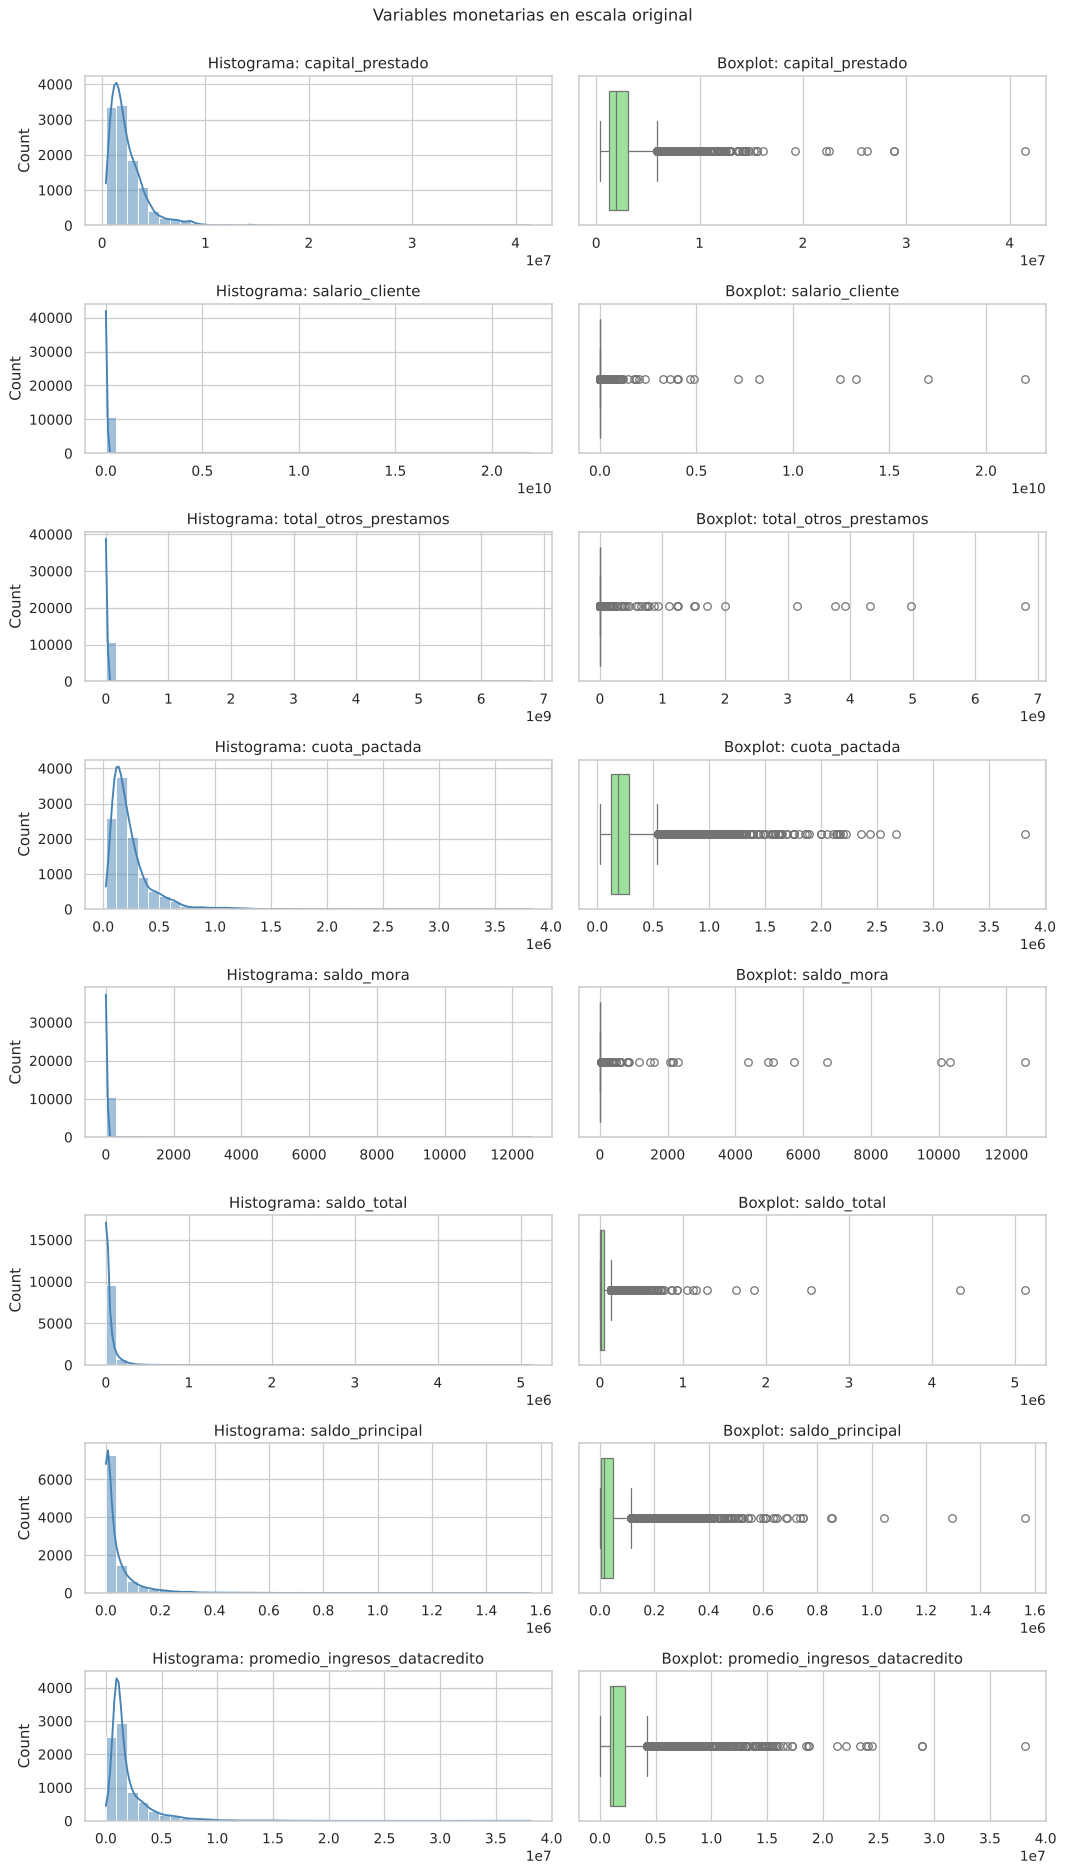

In [23]:
graficar_distribuciones(df, COLS_MONETARIAS, "Variables monetarias en escala original")

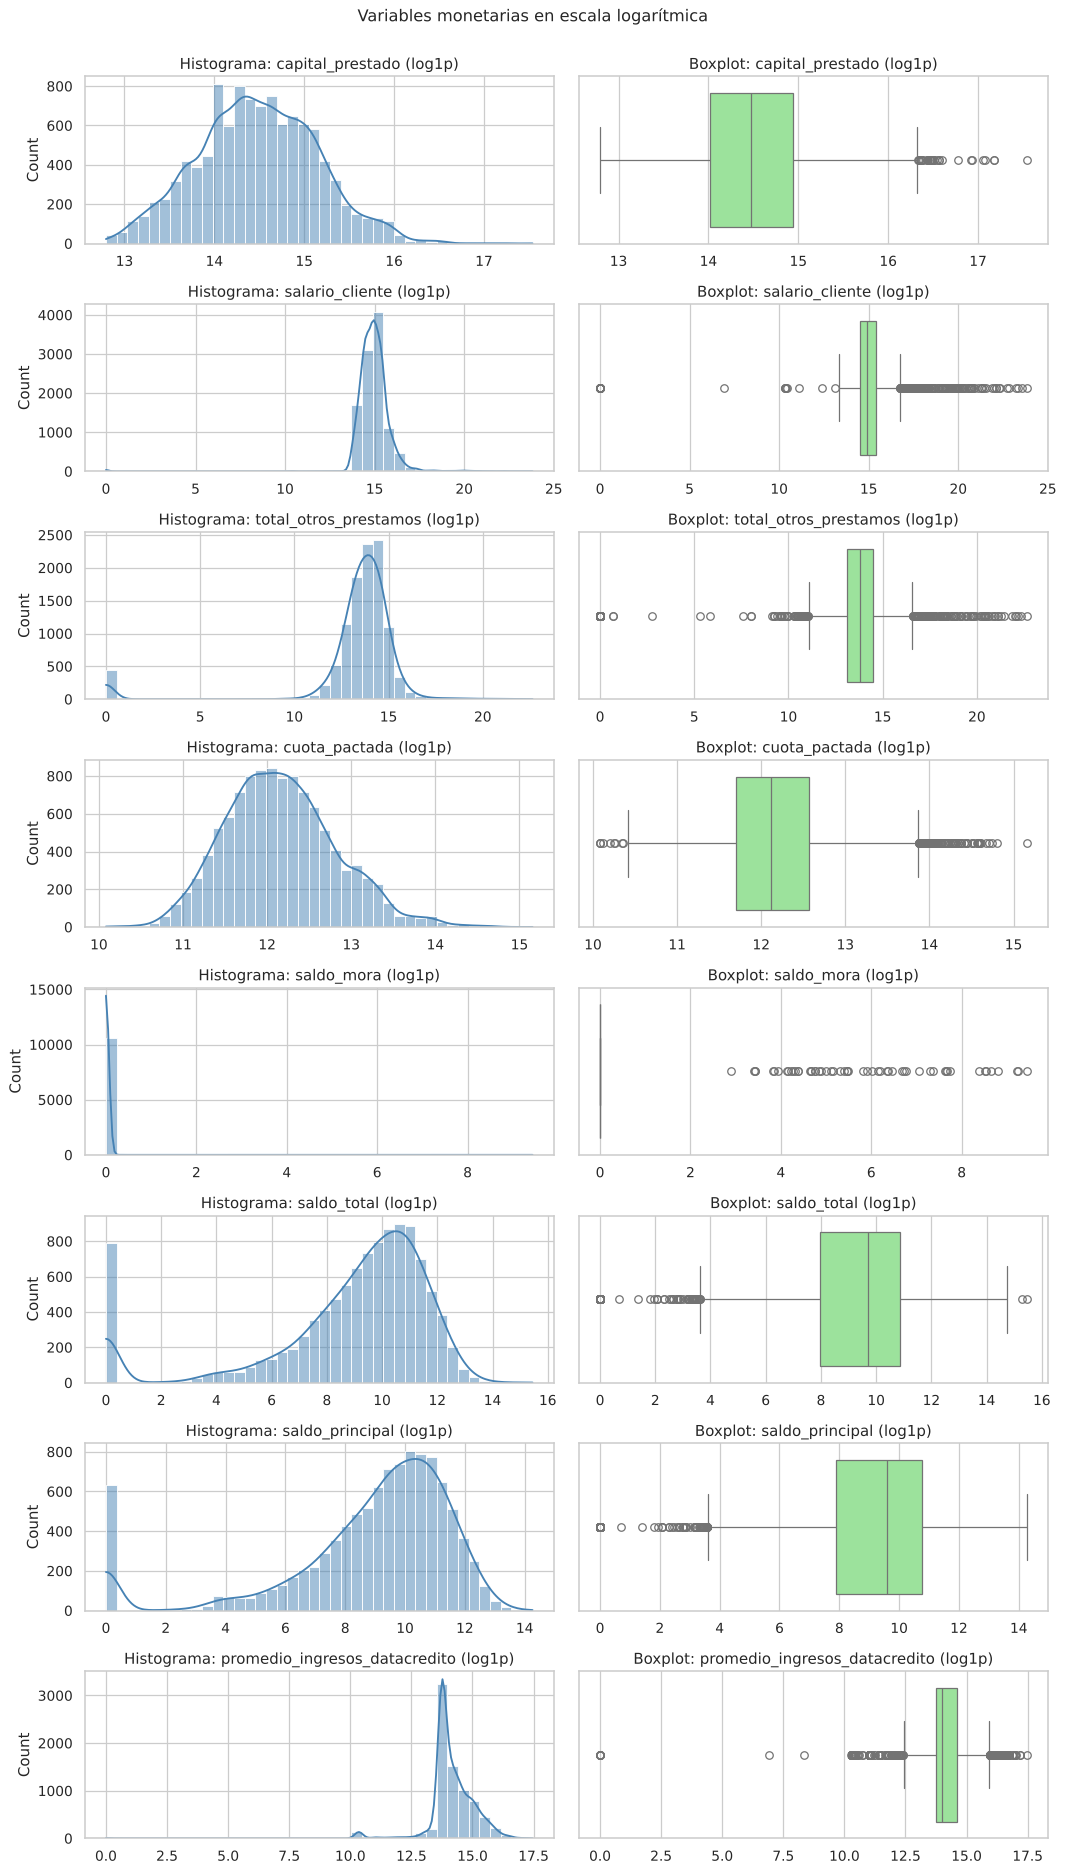

In [24]:
graficar_distribuciones(df, COLS_MONETARIAS, "Variables monetarias en escala logarítmica", log=True)

**Interpretación**

- En escala original las variables monetarias son ilegibles: los valores extremos comprimen toda
  la distribución contra el cero. Es la confirmación visual de la asimetría de la tabla 4.2.
- En escala logarítmica (`log1p`) `capital_prestado`, `cuota_pactada` y `total_otros_prestamos`
  toman una forma cercana a la campana: siguen aproximadamente una **distribución log-normal**.
  `salario_cliente` y `promedio_ingresos_datacredito` mejoran, pero conservan colas por los
  valores extremos. Los ceros aparecen como una barra separada a la izquierda. La transformación
  logarítmica es una buena candidata para estas variables (sección 8).
- `saldo_mora` sigue concentrada en cero incluso con logaritmo: es una variable con exceso de
  ceros (*zero-inflated*).

### 4.4 Tipo de distribución

Se combina la inspección visual con indicadores objetivos: asimetría, curtosis y la prueba de
normalidad de D'Agostino-Pearson, aplicada a la variable original y a su logaritmo. Con más de
10.000 registros cualquier prueba de normalidad rechaza por pequeñas desviaciones, así que el
p-valor se usa como referencia y la clasificación se basa sobre todo en la forma.

In [25]:
def clasificar_distribucion(serie: pd.Series) -> str:
    s = serie.dropna()
    if s.nunique() <= 2:
        return "Binaria"
    if (s == 0).mean() > 0.5:
        return "Concentrada en cero (zero-inflated)"
    asim = s.skew()
    if abs(asim) < 0.5:
        return "Aproximadamente simétrica (cercana a gaussiana)"
    positivos = s[s > 0]
    if asim > 1 and len(positivos) > 0.9 * len(s) and abs(np.log(positivos).skew()) < 1:
        return "Log-normal (sesgada a la derecha)"
    if asim > 0.5:
        return "Sesgada a la derecha"
    return "Sesgada a la izquierda"

filas = []
for col in COLS_NUMERICAS:
    s = df[col].dropna()
    p_original = stats.normaltest(s).pvalue
    # El logaritmo se evalúa solo sobre valores positivos para que los ceros no distorsionen la forma.
    positivos = s[s > 0]
    log_pos = np.log(positivos) if (s >= 0).all() and len(positivos) > 8 else None
    filas.append({
        "variable": col, "asimetria": s.skew(), "curtosis": s.kurt(),
        "asimetria_log_positivos": log_pos.skew() if log_pos is not None else np.nan,
        "%_ceros": (s == 0).mean() * 100,
        "p_normal": p_original,
        "p_normal_log": stats.normaltest(log_pos).pvalue if log_pos is not None else np.nan,
        "tipo_distribucion": clasificar_distribucion(s),
    })
tipo_distribucion = pd.DataFrame(filas).set_index("variable")
with pd.option_context("display.float_format", lambda v: f"{v:,.3f}"):
    display(tipo_distribucion)

,asimetria,curtosis,asimetria_log_positivos,%_ceros,p_normal,p_normal_log,tipo_distribucion
variable,,,,,,,
capital_prestado,3.724,35.318,0.112,0.000,0.000,0.000,Log-normal (sesgada a la derecha)
plazo_meses,2.460,7.780,0.325,0.000,0.000,0.000,Log-normal (sesgada a la derecha)
edad_cliente,0.268,-0.861,-0.204,0.000,0.000,0.000,Aproximadamente simétrica (cercana a gaussiana)
salario_cliente,43.777,"2,211.230",2.489,0.223,0.000,0.000,Sesgada a la derecha
total_otros_prestamos,38.464,"1,719.281",0.188,4.135,0.000,0.000,Log-normal (sesgada a la derecha)
cuota_pactada,3.793,26.651,0.402,0.000,0.000,0.000,Log-normal (sesgada a la derecha)
puntaje,-4.866,24.081,NaN,0.000,0.000,NaN,Sesgada a la izquierda
puntaje_datacredito,-0.686,5.233,-1.856,0.000,0.000,0.000,Sesgada a la izquierda
cant_creditosvigentes,1.798,8.623,-0.458,3.763,0.000,0.000,Log-normal (sesgada a la derecha)


**Interpretación**

- *Hecho:* ninguna variable pasa la prueba de normalidad (p-valor prácticamente 0). Con este tamaño
  de muestra es lo esperado y no invalida el análisis.
- *Hecho:* el logaritmo (sobre los valores positivos) reduce mucho la asimetría de las variables
  monetarias: `capital_prestado`, `cuota_pactada` y `total_otros_prestamos` quedan con asimetría
  inferior a 0,5, lo que respalda una distribución log-normal. `salario_cliente` pasa de más de 40
  a 2,5: mejora mucho, pero los salarios extremos siguen pesando, por lo que además del logaritmo
  conviene recortar los extremos. Los ceros (salario 0,
  sin otros préstamos, sin saldo) se tratan aparte: por eso conviene `log1p` o un indicador de cero.
- *Hecho:* `saldo_mora` (y en menor medida `creditos_sectorCooperativo`) se clasifican como
  concentradas en cero; para ellas es preferible una variable indicadora o una discretización.
- *Hecho:* `puntaje` y `puntaje_datacredito` están sesgadas a la izquierda, con la mayoría de los
  clientes en la parte alta de la escala.
- En las variables de conteo (`cant_creditosvigentes`, `huella_consulta`, `plazo_meses`) la
  etiqueta "log-normal" describe solo la forma asimétrica; al ser enteros, su modelo natural es
  una distribución de Poisson o binomial negativa.
- Ninguna variable presenta una distribución uniforme.

### 4.5 Variables categóricas: conteos, proporciones y tablas pivote

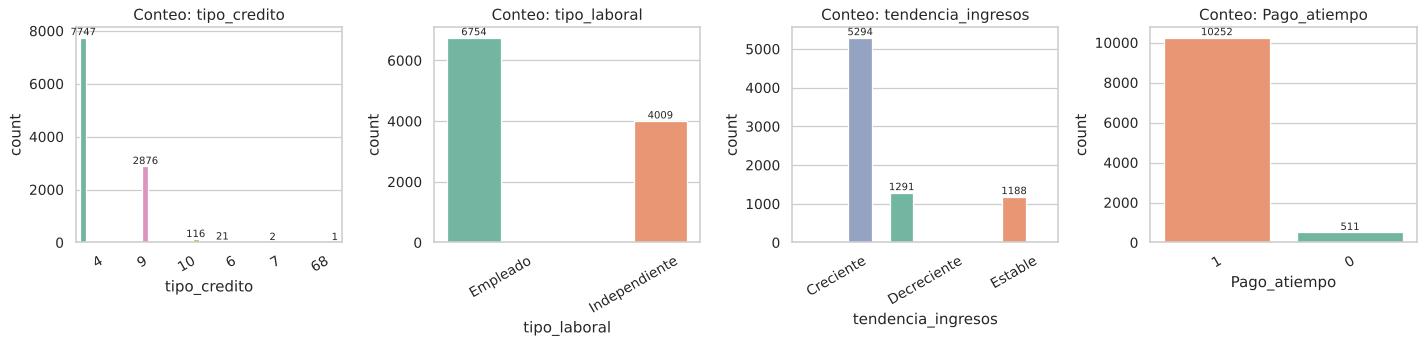

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, COLS_CATEGORICAS + [OBJETIVO]):
    orden = df[col].value_counts().index
    sns.countplot(data=df, x=col, hue=col, order=orden, legend=False, ax=ax)
    ax.set_title(f"Conteo: {col}")
    ax.tick_params(axis="x", rotation=30)
    for barra in ax.containers:
        ax.bar_label(barra, fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
for col in COLS_CATEGORICAS + [OBJETIVO]:
    tabla = pd.concat([
        df[col].value_counts(dropna=False).rename("conteo"),
        df[col].value_counts(dropna=False, normalize=True).mul(100).round(2).rename("porcentaje"),
    ], axis=1)
    print(f"\n{col}")
    display(tabla)


tipo_credito


,conteo,porcentaje
tipo_credito,,
4,7747,71.98
9,2876,26.72
10,116,1.08
6,21,0.20
7,2,0.02
68,1,0.01



tipo_laboral


,conteo,porcentaje
tipo_laboral,,
Empleado,6754,62.75
Independiente,4009,37.25



tendencia_ingresos


,conteo,porcentaje
tendencia_ingresos,,
Creciente,5294,49.19
NaN,2990,27.78
Decreciente,1291,11.99
Estable,1188,11.04



Pago_atiempo


,conteo,porcentaje
Pago_atiempo,,
1,10252,95.25
0,511,4.75


In [28]:
# Tabla pivote: monto, plazo y cuota medianos por tipo de crédito y tipo laboral.
pd.pivot_table(df, index="tipo_credito", columns="tipo_laboral",
               values=["capital_prestado", "plazo_meses", "cuota_pactada"],
               aggfunc="median", observed=True)

capital_prestado               cuota_pactada                \
tipo_laboral         Empleado Independiente      Empleado Independiente   
tipo_credito                                                              
4                1,879,620.00  2,016,000.00    165,440.50    207,528.00   
6                2,309,859.60           NaN    149,969.00           NaN   
7               12,542,263.20  3,692,160.00    212,394.00    341,296.00   
9                2,078,869.80  1,604,400.00    195,465.00    206,252.00   
10               2,655,360.00  1,528,560.00    197,933.00    142,366.00   
68               2,822,823.60           NaN     49,007.00           NaN   

             plazo_meses                
tipo_laboral    Empleado Independiente  
tipo_credito                            
4                  12.00          6.00  
6                  12.00           NaN  
7                  90.00         10.00  
9                  10.00          9.00  
10                 12.00         12.00  
68                 48.00           NaN

In [29]:
# Tabla pivote: número de créditos por tipo de crédito y tendencia de ingresos.
pd.pivot_table(df.assign(n=1), index="tipo_credito", columns="tendencia_ingresos", values="n",
               aggfunc="sum", fill_value=0, observed=False, margins=True, margins_name="Total")

tendencia_ingresos,Decreciente,Estable,Creciente,Total
tipo_credito,,,,
4,993,900,3855,5748
6,3,0,14,17
7,0,1,0,1
9,286,270,1363,1919
10,9,17,61,87
68,0,0,1,1
Total,1291,1188,5294,7773


**Interpretación**

- `tipo_credito`: dos productos concentran casi todo el portafolio (código 4 con el 72 % y
  código 9 con el 27 %). Los códigos 6, 7, 10 y 68 suman menos del 2 %; los códigos 7 y 68 tienen
  1 o 2 registros, insuficientes para que un modelo aprenda algo de ellos.
- `tipo_laboral`: 63 % empleados y 37 % independientes; está razonablemente balanceada.
- `tendencia_ingresos`: entre los valores válidos predomina "Creciente" (49 % del total). Los
  nulos (28 %, incluidos los 58 valores corregidos en 3.5) son la segunda categoría más grande,
  por lo que su tratamiento es importante.
- Tablas pivote: en el producto 4 los independientes reciben un capital mediano algo mayor que
  los empleados, pero a la mitad de plazo (6 frente a 12 meses), por lo que pagan cuotas más altas.
  En el producto 9 ocurre lo contrario con el capital (los empleados reciben más). Las filas de los
  productos 6, 7 y 68 se basan en muy pocos créditos y no deben interpretarse.

### 4.6 Dimensión temporal

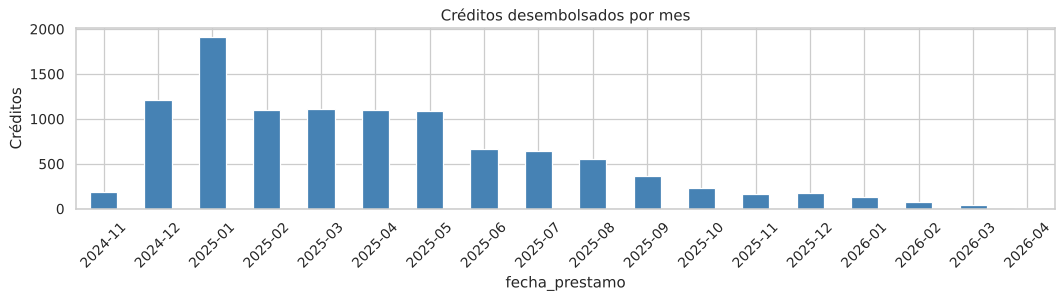

Rango de fechas: 2024-11-26 09:17:04 a 2026-04-26 18:43:52


In [30]:
creditos_mes = df.groupby(df["fecha_prestamo"].dt.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 3.5))
creditos_mes.plot(kind="bar", ax=ax, color="steelblue")
ax.set_xticklabels([str(p) for p in creditos_mes.index], rotation=45)
ax.set_title("Créditos desembolsados por mes")
ax.set_ylabel("Créditos")
plt.tight_layout()
plt.show()
print(f"Rango de fechas: {df['fecha_prestamo'].min()} a {df['fecha_prestamo'].max()}")

**Interpretación**

- *Hecho:* los créditos van de noviembre de 2024 a abril de 2026. El volumen alcanza su máximo en
  enero de 2025 (1.917 créditos) y cae de forma continua desde mediados de 2025 hasta 11 créditos
  en abril de 2026.
- *Hipótesis:* la caída puede deberse a que los créditos recientes todavía no tienen definido el
  resultado de pago y se excluyeron del extracto, o a un cambio en la originación. Se debe
  confirmar, porque afecta a cómo se construye la variable objetivo y a la partición temporal
  de entrenamiento y validación.

## 5. Análisis bivariable respecto a la variable objetivo

### 5.1 Distribución de la variable objetivo

In [31]:
balance = df[OBJETIVO].value_counts().to_frame("conteo")
balance["porcentaje"] = balance["conteo"] / balance["conteo"].sum() * 100
display(balance)
print(f"Razón de desbalance: {balance.loc[1, 'conteo'] / balance.loc[0, 'conteo']:.1f} pagos a tiempo por cada impago")

,conteo,porcentaje
Pago_atiempo,,
1,10252,95.25
0,511,4.75


Razón de desbalance: 20.1 pagos a tiempo por cada impago


**Interpretación**

- *Hecho:* el 95,3 % de los créditos se pagó a tiempo y solo el 4,7 % (511 casos) no. Es un problema
  **muy desbalanceado** (unos 20 a 1).
- *Consecuencias para el modelado:* la exactitud (*accuracy*) no sirve como métrica, porque un
  modelo que siempre prediga "pagó" acierta el 95 %. Hay que usar métricas centradas en la clase
  minoritaria (recall y precisión de la clase 0, F1, AUC-PR), particiones estratificadas y alguna
  técnica de balanceo (pesos de clase o sobremuestreo aplicado solo en entrenamiento).

### 5.2 Variables numéricas frente al objetivo

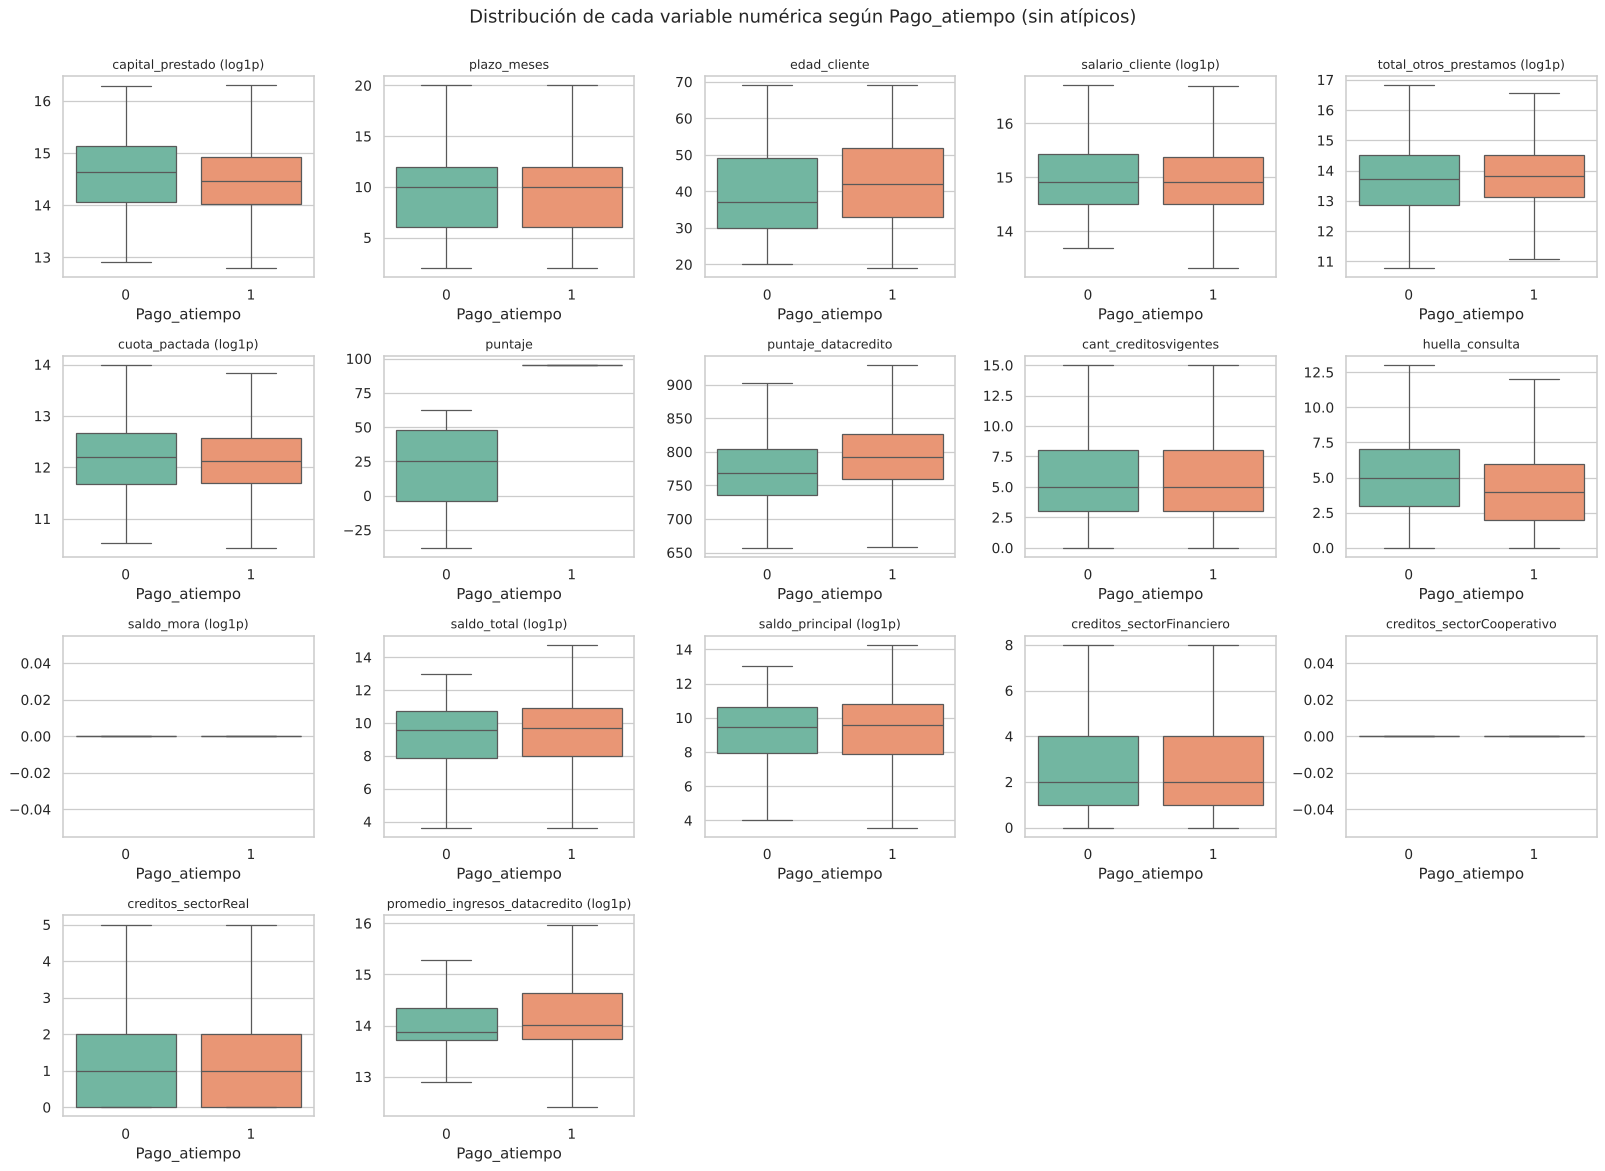

In [32]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, col in zip(axes.ravel(), COLS_NUMERICAS):
    datos = df[[col, OBJETIVO]].dropna()
    usar_log = col in COLS_MONETARIAS
    if usar_log:
        datos[col] = np.log1p(datos[col].clip(lower=0))
    sns.boxplot(data=datos, x=OBJETIVO, y=col, hue=OBJETIVO, legend=False, ax=ax, showfliers=False)
    ax.set_title(col + (" (log1p)" if usar_log else ""), fontsize=10)
    ax.set_ylabel("")
for ax in axes.ravel()[len(COLS_NUMERICAS):]:
    ax.set_visible(False)
plt.suptitle("Distribución de cada variable numérica según Pago_atiempo (sin atípicos)", y=1.0)
plt.tight_layout()
plt.show()

In [33]:
# Comparación de medianas y prueba de Mann-Whitney (no paramétrica, adecuada para distribuciones
# sesgadas). El tamaño del efecto se mide con la correlación biserial de rangos: valores cercanos
# a 0 indican que la variable apenas separa las clases.
filas = []
for col in COLS_NUMERICAS:
    g0 = df.loc[df[OBJETIVO] == 0, col].dropna()
    g1 = df.loc[df[OBJETIVO] == 1, col].dropna()
    u, p = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    filas.append({
        "variable": col, "mediana_no_pago": g0.median(), "mediana_pago": g1.median(),
        "media_no_pago": g0.mean(), "media_pago": g1.mean(),
        "efecto_rango_biserial": 1 - 2 * u / (len(g0) * len(g1)), "p_valor": p,
    })
comparacion_num = pd.DataFrame(filas).set_index("variable").sort_values(
    "efecto_rango_biserial", key=np.abs, ascending=False)
with pd.option_context("display.float_format", lambda v: f"{v:,.3f}"):
    display(comparacion_num)

,mediana_no_pago,mediana_pago,media_no_pago,media_pago,efecto_rango_biserial,p_valor
variable,,,,,,
puntaje,25.419,95.228,23.091,94.563,1.000,0.000
puntaje_datacredito,769.000,792.000,763.858,792.981,0.248,0.000
huella_consulta,5.000,4.000,5.241,4.178,-0.196,0.000
edad_cliente,37.000,42.000,40.008,42.986,0.152,0.000
promedio_ingresos_datacredito,"1,052,529.000","1,211,296.000","1,605,742.050","2,023,447.768",0.145,0.000
capital_prestado,"2,268,000.000","1,908,446.400","2,781,774.113","2,416,996.273",-0.114,0.000
creditos_sectorFinanciero,2.000,2.000,2.517,2.793,0.081,0.002
total_otros_prestamos,"900,000.000","1,000,000.000","11,564,401.926","5,973,424.175",0.071,0.007
creditos_sectorReal,1.000,1.000,1.493,1.293,-0.047,0.059


**Interpretación** (efecto positivo: el grupo que no pagó tiene valores **menores**; negativo: valores mayores)

- *Hecho:* `puntaje` es, con enorme diferencia, la variable que más separa las clases (mediana
  cercana a 25 en los impagos frente a 95 en los pagos). Refuerza la sospecha de fuga de
  información de la sección 3.4.
- *Hecho:* entre las demás variables, las que muestran diferencias más claras son:
  - `puntaje_datacredito`: los impagos tienen un puntaje de central menor (mediana alrededor de 770
    frente a 790);
  - `huella_consulta`: los impagos tienen más consultas recientes en la central, lo que es
    coherente con clientes que buscan crédito en varias entidades;
  - `edad_cliente`: los impagos son más jóvenes (mediana de 37 frente a 42 años);
  - `promedio_ingresos_datacredito`: los impagos tienen menor ingreso estimado por la central;
  - `capital_prestado`: los créditos que no se pagaron eran de mayor monto (mediana de 2,27
    frente a 1,91 millones).
- *Hecho:* `plazo_meses` no muestra una diferencia significativa en la prueba global (p = 0,10),
  porque la mediana es 10 meses en ambos grupos; la diferencia está en la cola: los plazos largos
  concentran más impagos (se ve en 5.2 por cuartiles y en 6.4).
- *Hecho:* `salario_cliente` no separa las clases (p = 0,62): el ingreso declarado, por sí solo, no
  informa sobre el pago.
- *Hecho:* la media de `saldo_mora` es mucho más alta en los impagos, aunque la mediana es 0 en
  ambos grupos: la diferencia la explican pocos clientes con mora previa.
- *Inferencia:* aparte de `puntaje`, ninguna variable separa las clases por sí sola (efectos
  pequeños). El modelo tendrá que combinar varias señales débiles, lo que favorece modelos no
  lineales o de árboles.

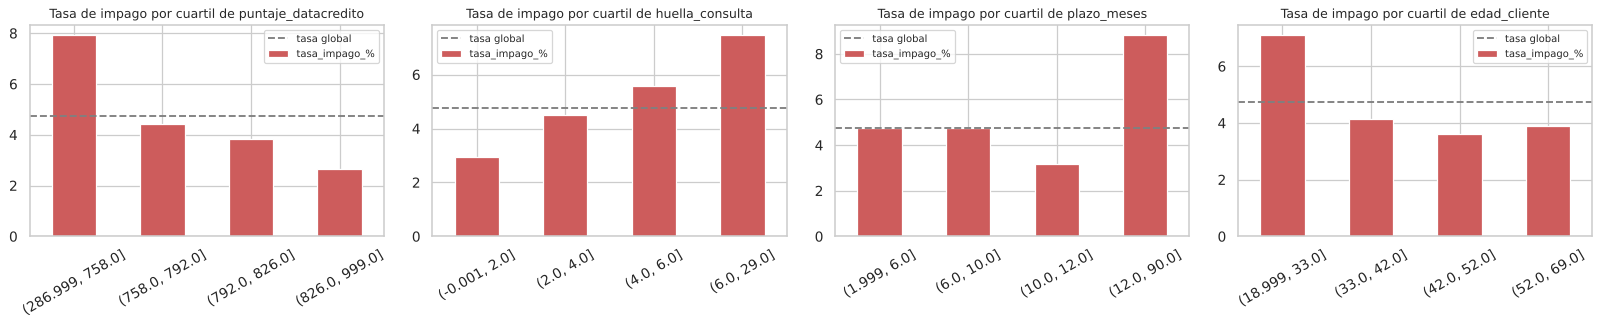

In [34]:
# Tasa de impago por cuartil de las variables más relevantes: muestra si la relación es monótona.
TASA = "tasa_impago_%"
def tasa_impago_por_grupo(datos, grupo):
    return (datos.groupby(grupo, observed=True)[OBJETIVO]
                 .agg(n="size", tasa=lambda s: (1 - s.mean()) * 100)
                 .rename(columns={"tasa": TASA}))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, ["puntaje_datacredito", "huella_consulta", "plazo_meses", "edad_cliente"]):
    cuartiles = pd.qcut(df[col], q=4, duplicates="drop")
    tabla = tasa_impago_por_grupo(df.assign(cuartil=cuartiles), "cuartil")
    tabla[TASA].plot(kind="bar", ax=ax, color="indianred")
    ax.axhline((1 - df[OBJETIVO].mean()) * 100, ls="--", color="grey", label="tasa global")
    ax.set_title(f"Tasa de impago por cuartil de {col}", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretación**

- La tasa de impago **baja** a medida que sube `puntaje_datacredito` (del 7,9 % en el cuartil
  más bajo al 2,6 % en el más alto) y **sube** con `huella_consulta` (del 2,9 % al 7,5 %). Son
  relaciones monótonas y con sentido de negocio.
- Por plazo, la tasa es similar hasta 12 meses y casi se duplica en el cuartil de plazos de
  más de 12 meses (8,8 %).
- Por edad, el cuartil más joven (hasta 33 años) tiene una tasa del 7,1 %, frente a menos del 4,2 %
  en los demás: el efecto se concentra en los clientes jóvenes.

### 5.3 Variables categóricas frente al objetivo

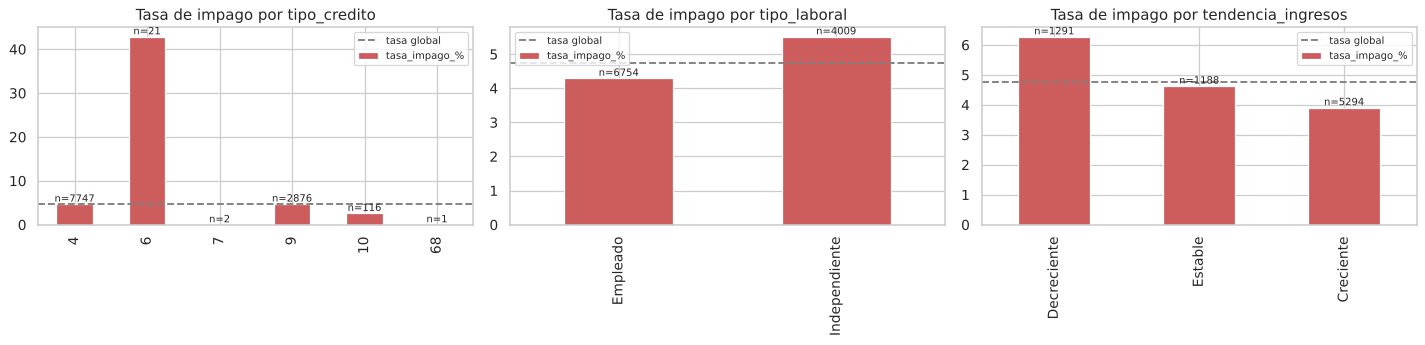

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, COLS_CATEGORICAS):
    tabla = tasa_impago_por_grupo(df, col)
    tabla[TASA].plot(kind="bar", ax=ax, color="indianred")
    ax.axhline((1 - df[OBJETIVO].mean()) * 100, ls="--", color="grey", label="tasa global")
    ax.set_title(f"Tasa de impago por {col}")
    ax.set_xlabel("")
    ax.legend(fontsize=8)
    for i, n in enumerate(tabla["n"]):
        ax.annotate(f"n={n}", (i, tabla[TASA].iloc[i]), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

In [36]:
# Tablas cruzadas normalizadas por fila y prueba chi-cuadrado de independencia.
for col in COLS_CATEGORICAS:
    tabla = pd.crosstab(df[col], df[OBJETIVO], margins=True)
    proporciones = pd.crosstab(df[col], df[OBJETIVO], normalize="index").mul(100).round(2)
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df[col], df[OBJETIVO]))
    print(f"\n{col}: chi2 = {chi2:.2f}, p-valor = {p:.4f}")
    display(tabla.join(proporciones, rsuffix="_%"))

# Los nulos de tendencia_ingresos como categoría propia.
print("\nTasa de impago con nulos de tendencia_ingresos como categoría:")
tendencia_con_nulos = df["tendencia_ingresos"].cat.add_categories("Sin dato").fillna("Sin dato")
tasa_impago_por_grupo(df.assign(tendencia=tendencia_con_nulos), "tendencia")


tipo_credito: chi2 = 68.86, p-valor = 0.0000


Pago_atiempo,0,1,All,0_%,1_%
tipo_credito,,,,,
4,363,7384,7747,4.69,95.31
6,9,12,21,42.86,57.14
7,0,2,2,0.00,100.00
9,136,2740,2876,4.73,95.27
10,3,113,116,2.59,97.41
68,0,1,1,0.00,100.00
All,511,10252,10763,NaN,NaN



tipo_laboral: chi2 = 8.00, p-valor = 0.0047


Pago_atiempo,0,1,All,0_%,1_%
tipo_laboral,,,,,
Empleado,290,6464,6754,4.29,95.71
Independiente,221,3788,4009,5.51,94.49
All,511,10252,10763,NaN,NaN



tendencia_ingresos: chi2 = 13.91, p-valor = 0.0010


Pago_atiempo,0,1,All,0_%,1_%
tendencia_ingresos,,,,,
Decreciente,81,1210,1291,6.27,93.73
Estable,55,1133,1188,4.63,95.37
Creciente,207,5087,5294,3.91,96.09
All,343,7430,7773,NaN,NaN



Tasa de impago con nulos de tendencia_ingresos como categoría:


,n,tasa_impago_%
tendencia,,
Decreciente,1291,6.27
Estable,1188,4.63
Creciente,5294,3.91
Sin dato,2990,5.62


**Interpretación**

- `tipo_credito`: el producto 6 tiene una tasa de impago muy superior al resto (alrededor de 43 %),
  aunque con solo 21 créditos la estimación es poco estable. Los productos principales (4 y 9)
  están en la media.
- `tipo_laboral`: los independientes incumplen algo más (5,5 %) que los empleados (4,3 %). La
  diferencia es estadísticamente significativa, pero pequeña.
- `tendencia_ingresos`: "Decreciente" tiene la tasa de impago más alta (6,3 %) y "Creciente" la más
  baja (3,9 %), en el orden esperado, lo que respalda codificarla como ordinal. Los nulos
  ("Sin dato") tienen una tasa del 5,6 %, superior a la global, lo que confirma que el nulo es
  informativo y debe conservarse como categoría propia.

### 5.4 Evolución del objetivo en el tiempo

In [37]:
por_trimestre = tasa_impago_por_grupo(df.assign(trimestre=df["fecha_prestamo"].dt.to_period("Q")), "trimestre")
display(por_trimestre)

,n,tasa_impago_%
trimestre,,
2024Q4,1402,6.21
2025Q1,4126,5.02
2025Q2,2850,4.95
2025Q3,1560,3.01
2025Q4,571,2.45
2026Q1,243,5.76
2026Q2,11,9.09


**Interpretación**

- La tasa de impago varía entre trimestres (6,2 % en el cuarto trimestre de 2024 y 2,5 % en el
  cuarto de 2025). Los trimestres finales tienen pocos créditos y sus tasas son poco fiables.
- *Inferencia:* el comportamiento no es estable en el tiempo. Para evaluar el modelo conviene
  reservar los créditos más recientes como validación temporal (*out-of-time*) además de la
  validación aleatoria, y monitorear la deriva de la tasa de impago una vez en producción.

## 6. Análisis multivariable

### 6.1 Matrices de correlación

Se presentan Pearson (relación lineal) y Spearman (relación monótona, robusta a atípicos). Dada
la asimetría de las variables, Spearman es la referencia principal.

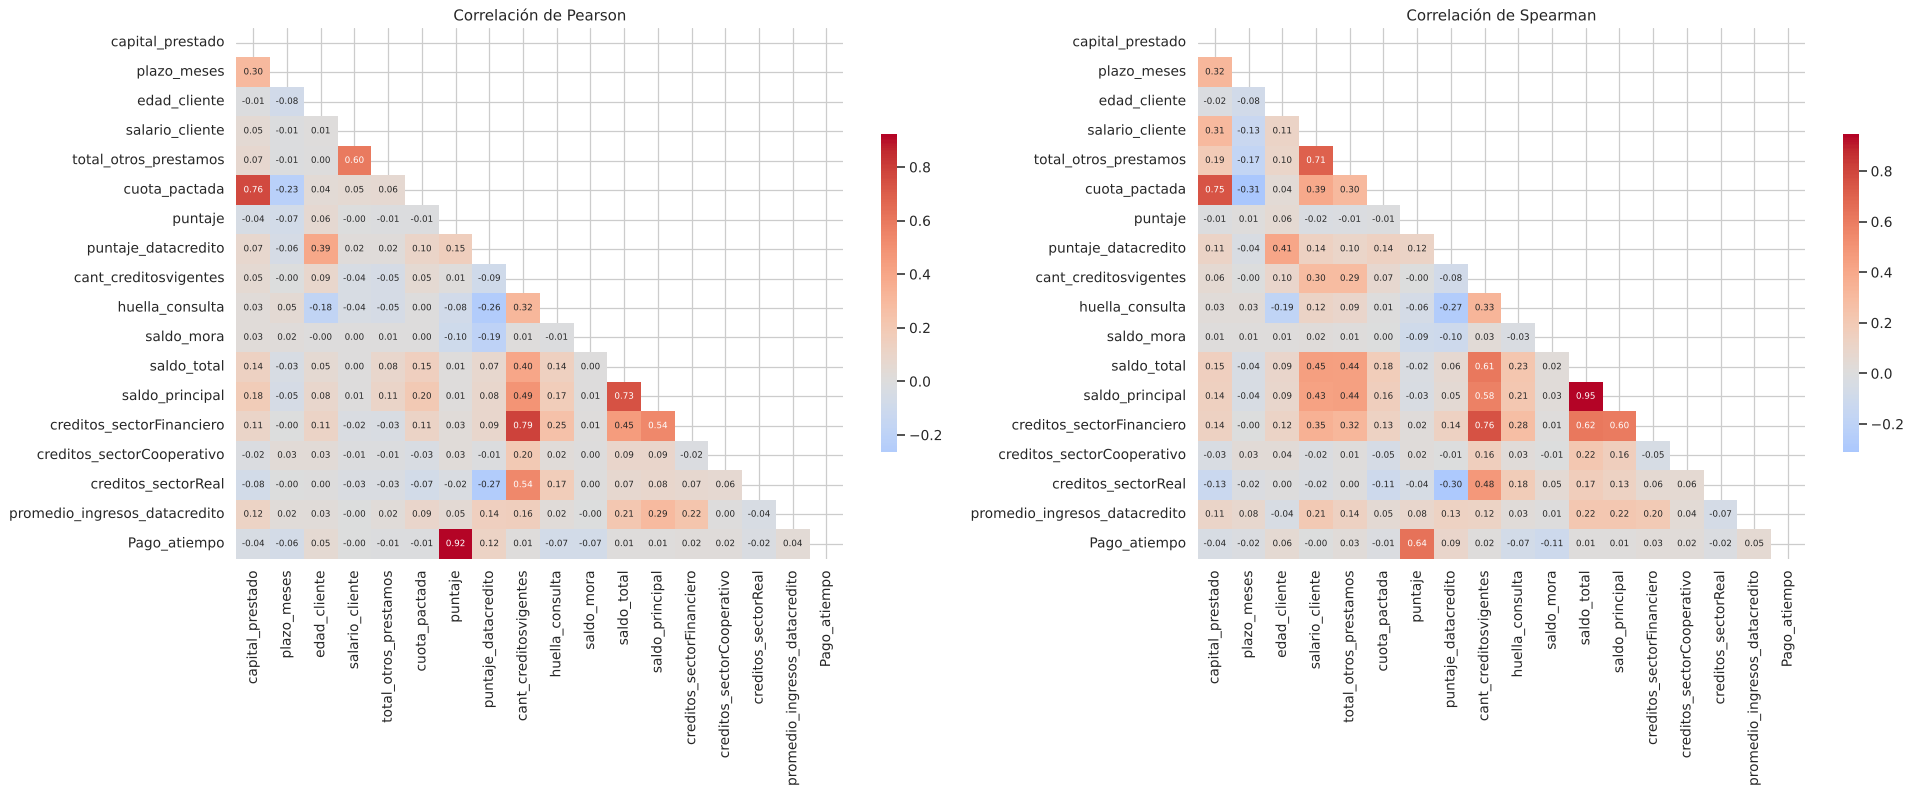

In [38]:
cols_corr = COLS_NUMERICAS + [OBJETIVO]
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    matriz = df[cols_corr].corr(method=metodo)
    mascara = np.triu(np.ones_like(matriz, dtype=bool))
    sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.6})
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

In [39]:
# Pares de variables explicativas con correlación alta (posible multicolinealidad).
spearman = df[COLS_NUMERICAS].corr(method="spearman")
pares = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack()
                 .rename("spearman").to_frame())
pares["abs"] = pares["spearman"].abs()
pares.query("abs >= 0.6").sort_values("abs", ascending=False).drop(columns="abs")

,,spearman
saldo_total,saldo_principal,0.95
cant_creditosvigentes,creditos_sectorFinanciero,0.76
capital_prestado,cuota_pactada,0.75
salario_cliente,total_otros_prestamos,0.71
saldo_total,creditos_sectorFinanciero,0.62
cant_creditosvigentes,saldo_total,0.61
saldo_principal,creditos_sectorFinanciero,0.60


**Interpretación**

- *Hecho:* los pares más correlacionados tienen una explicación de negocio:
  - `saldo_total` y `saldo_principal` (0,95): el saldo principal es parte del saldo total;
  - `cant_creditosvigentes` y `creditos_sectorFinanciero` (0,76): el total de créditos vigentes
    se compone de los créditos por sector;
  - `capital_prestado` y `cuota_pactada` (0,75): la cuota depende del monto y del plazo;
  - `salario_cliente` y `total_otros_prestamos` (0,71): quien declara más ingreso tiene más deuda
    con otras entidades;
  - los saldos se correlacionan también con el número de créditos con el sector financiero
    (alrededor de 0,6).
- *Inferencia:* hay redundancia. Para modelos lineales conviene quedarse con una variable por
  grupo o sustituirlas por ratios (sección 9); los modelos de árboles toleran mejor esta redundancia.
- *Hecho:* con la correlación de Pearson, la relación de las variables monetarias es más débil
  que con Spearman, porque los atípicos distorsionan la medida lineal.
- *Hecho:* fuera de `puntaje`, ninguna variable tiene una correlación con el objetivo mayor que
  0,1 en valor absoluto, lo que coincide con lo visto en 5.2.

### 6.2 Pairplot con la variable objetivo como `hue`

Se usa una muestra estratificada para que el gráfico sea legible y rápido. Las variables
monetarias se muestran en escala logarítmica.

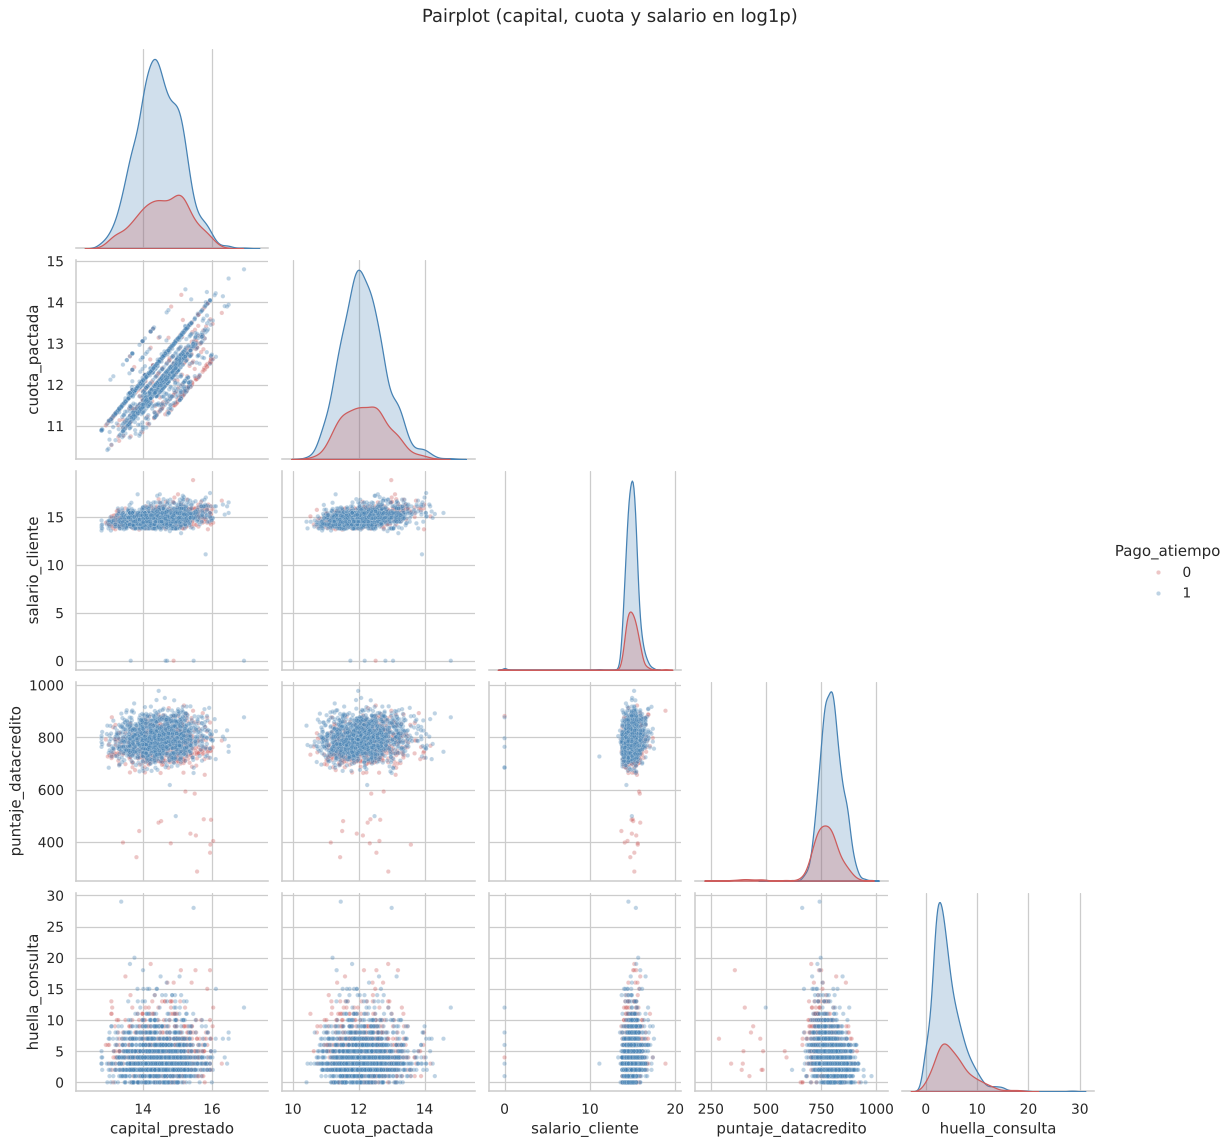

In [40]:
COLS_PAIRPLOT = ["capital_prestado", "cuota_pactada", "salario_cliente", "puntaje_datacredito", "huella_consulta"]
# Hasta 1.500 registros por clase: se incluyen todos los impagos y una muestra de los pagos.
muestra = pd.concat([grupo.sample(n=min(len(grupo), 1500), random_state=42)
                     for _, grupo in df.groupby(OBJETIVO)])[COLS_PAIRPLOT + [OBJETIVO]].dropna()
for col in ["capital_prestado", "cuota_pactada", "salario_cliente"]:
    muestra[col] = np.log1p(muestra[col])
g = sns.pairplot(muestra, hue=OBJETIVO, corner=True, plot_kws={"alpha": 0.35, "s": 12},
                 diag_kind="kde", palette={0: "indianred", 1: "steelblue"})
g.figure.suptitle("Pairplot (capital, cuota y salario en log1p)", y=1.02)
plt.show()

**Interpretación**

- La relación entre `capital_prestado` y `cuota_pactada` es claramente lineal en escala logarítmica,
  con "bandas" que corresponden a los distintos plazos.
- Las nubes de puntos de ambas clases se superponen en todas las combinaciones: no hay ninguna
  región del espacio donde se concentren los impagos. Esto confirma que el problema es difícil
  y que el modelo deberá combinar varias variables.
- En la diagonal, la densidad de `puntaje_datacredito` de los impagos está desplazada hacia valores
  más bajos, y la de `huella_consulta` hacia valores más altos.

### 6.3 Gráficos de dispersión con `hue` categórico

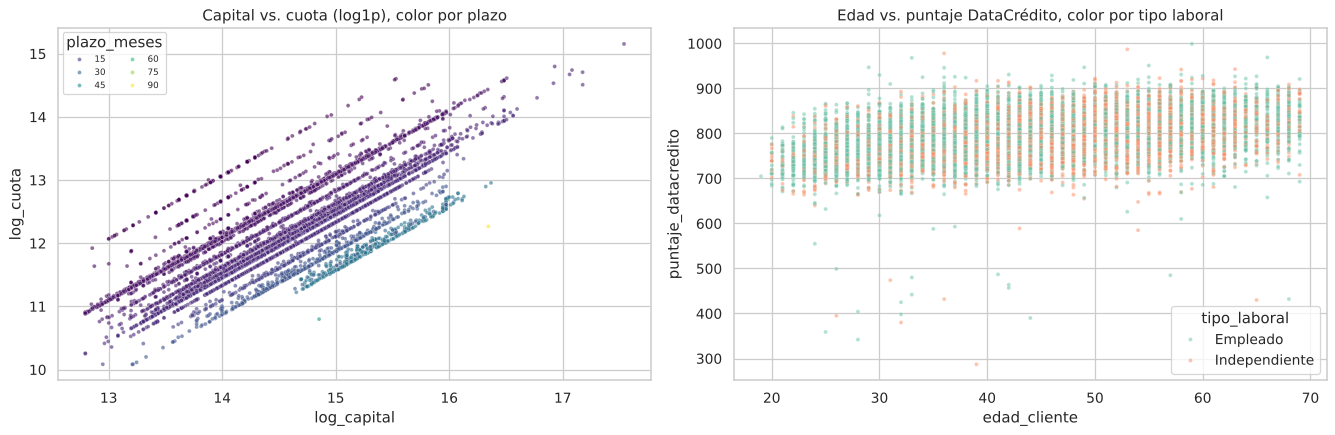

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
datos = df.assign(log_capital=np.log1p(df["capital_prestado"]), log_cuota=np.log1p(df["cuota_pactada"]))
sns.scatterplot(data=datos, x="log_capital", y="log_cuota", hue="plazo_meses", palette="viridis",
                s=10, alpha=0.6, ax=axes[0])
axes[0].set_title("Capital vs. cuota (log1p), color por plazo")
axes[0].legend(title="plazo_meses", fontsize=7, ncol=2)
sns.scatterplot(data=datos, x="edad_cliente", y="puntaje_datacredito", hue="tipo_laboral",
                s=10, alpha=0.5, ax=axes[1])
axes[1].set_title("Edad vs. puntaje DataCrédito, color por tipo laboral")
plt.tight_layout()
plt.show()

**Interpretación**

- A igual capital, los plazos más largos (colores claros) tienen cuotas más bajas: la cuota es
  una función casi determinista del capital y el plazo. Por eso la cuota aporta poca información
  nueva frente a esas dos variables, pero el cociente cuota/salario sí puede aportar (capacidad de pago).
- El puntaje de la central aumenta con la edad (correlación de Spearman de 0,41). No hay una
  diferencia clara entre empleados e independientes (medianas de 790 y 794).
- *Inferencia:* parte del efecto de la edad sobre el impago puede venir de su relación con el
  puntaje de la central; el modelo debe evaluar ambas variables juntas.

### 6.4 Tablas cruzadas entre varias variables

In [42]:
# Tasa de impago (%) por tipo laboral y tendencia de ingresos.
pd.pivot_table(df, index="tipo_laboral", columns="tendencia_ingresos", values=OBJETIVO,
               aggfunc=lambda s: (1 - s.mean()) * 100, observed=True).round(2)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,5.87,4.49,3.56
Independiente,7.34,4.80,4.82


In [43]:
# Tasa de impago (%) y número de créditos por producto principal y rango de plazo.
rango_plazo = pd.cut(df["plazo_meses"], bins=[0, 6, 12, 24, 120], labels=["<=6", "7-12", "13-24", ">24"])
principales = df["tipo_credito"].isin([4, 9])
pd.pivot_table(df[principales].assign(rango_plazo=rango_plazo[principales]),
               index="tipo_credito", columns="rango_plazo", values=OBJETIVO,
               aggfunc=[lambda s: round((1 - s.mean()) * 100, 2), "size"], observed=True)

<lambda>                      size                       
rango_plazo       <=6 7-12 13-24   >24      <=6     7-12  13-24    >24
tipo_credito                                                          
4                4.76 3.35  6.66 12.33 3,236.00 3,402.00 736.00 373.00
9                4.82 4.70   NaN   NaN   622.00 2,254.00    NaN    NaN

**Interpretación**

- La combinación **independiente + ingresos decrecientes** tiene la tasa de impago más alta de la
  tabla. Es una interacción de dos señales débiles que se refuerzan.
- En el producto 4 la tasa de impago crece con el plazo: 6,7 % entre 13 y 24 meses y 12,3 % por
  encima de 24 meses, frente a menos del 5 % en plazos de hasta 12 meses. El producto 9 solo se
  otorga hasta 12 meses y no muestra esa diferencia.
- *Inferencia:* el efecto del plazo es una interacción con el producto; un modelo de árboles la
  captura directamente, y en uno lineal habría que crear la interacción de forma explícita.

## 7. Reglas de validación de datos

Las reglas se derivan de los hallazgos anteriores y se usarán en la etapa de validación del
pipeline. Cada regla tiene una severidad:

- **error**: el registro no se puede usar tal como está (se rechaza o se corrige a nulo);
- **alerta**: el registro es válido, pero sospechoso, y debe monitorearse.

Los límites basados en negocio (por ejemplo, la edad mínima o el rango del puntaje de la central)
son *hipótesis* a confirmar. Las reglas se evalúan sobre `df_raw` para medir cuántos registros
originales incumplen cada una.

In [44]:
REGLAS_VALIDACION = [
    # (id, columna, descripción, severidad, función que devuelve True cuando el registro INCUMPLE)
    ("R01", "esquema", "Existen las 23 columnas esperadas", "error", None),
    ("R02", OBJETIVO, "Objetivo no nulo y en {0, 1}", "error", lambda d: ~d[OBJETIVO].isin([0, 1])),
    ("R03", "tipo_credito", "Código en el catálogo conocido {4, 6, 7, 9, 10}", "alerta",
        lambda d: ~d["tipo_credito"].isin([4, 6, 7, 9, 10])),
    ("R04", "fecha_prestamo", "Fecha válida y no futura", "error",
        lambda d: pd.to_datetime(d["fecha_prestamo"], errors="coerce").isna()
                  | (pd.to_datetime(d["fecha_prestamo"], errors="coerce") > pd.Timestamp.today())),
    ("R05", "capital_prestado", "Capital > 0", "error", lambda d: ~(d["capital_prestado"] > 0)),
    ("R06", "plazo_meses", "Plazo entero entre 1 y 60 meses", "alerta",
        lambda d: ~d["plazo_meses"].between(1, 60)),
    ("R07", "edad_cliente", "Edad entre 18 y 100 años", "error",
        lambda d: ~d["edad_cliente"].between(18, 100)),
    ("R08", "tipo_laboral", "Valor en {Empleado, Independiente}", "error",
        lambda d: ~d["tipo_laboral"].isin(["Empleado", "Independiente"])),
    ("R09", "salario_cliente", "Salario > 0", "alerta", lambda d: ~(d["salario_cliente"] > 0)),
    ("R10", "salario_cliente", "Salario <= 100 millones mensuales", "alerta",
        lambda d: d["salario_cliente"] > 1e8),
    ("R11", "cuota_pactada", "Cuota > 0 y menor o igual que el capital", "error",
        lambda d: ~((d["cuota_pactada"] > 0) & (d["cuota_pactada"] <= d["capital_prestado"]))),
    ("R12", "cuota_pactada", "Cuota / salario <= 1 (la cuota no supera el ingreso)", "alerta",
        lambda d: (d["cuota_pactada"] / d["salario_cliente"].replace(0, np.nan)) > 1),
    ("R13", "puntaje_datacredito", "Puntaje entre 100 y 999 (valores menores = sin dato)", "error",
        lambda d: d["puntaje_datacredito"].notna() & ~d["puntaje_datacredito"].between(100, 999)),
    ("R14", "conteos", "Conteos (créditos, huella, sectores) enteros y >= 0", "error",
        lambda d: (d[["cant_creditosvigentes", "huella_consulta", "creditos_sectorFinanciero",
                      "creditos_sectorCooperativo", "creditos_sectorReal"]] < 0).any(axis=1)),
    ("R15", "saldos", "Saldos (mora, total, principal) >= 0", "error",
        lambda d: (d[["saldo_mora", "saldo_total", "saldo_principal"]] < 0).any(axis=1)),
    ("R16", "saldo_principal", "Saldo principal <= saldo total", "alerta",
        lambda d: d["saldo_principal"] > d["saldo_total"]),
    ("R17", "tendencia_ingresos", "Valor en {Creciente, Decreciente, Estable} o nulo", "error",
        lambda d: d["tendencia_ingresos"].notna()
                  & ~d["tendencia_ingresos"].isin(["Creciente", "Decreciente", "Estable"])),
    ("R18", "promedio_ingresos_datacredito", "Promedio y tendencia de ingresos nulos a la vez o informados a la vez", "alerta",
        lambda d: d["promedio_ingresos_datacredito"].isna() != d["tendencia_ingresos"].isna()),
    ("R19", "nulos", "% de nulos por columna dentro de lo observado en el EDA (máx. 30 %)", "alerta", None),
]

def evaluar_reglas(datos: pd.DataFrame) -> pd.DataFrame:
    resultados = []
    for id_regla, columna, descripcion, severidad, funcion in REGLAS_VALIDACION:
        if id_regla == "R01":
            incumple = len(set(diccionario["variable"]) - set(datos.columns))
        elif id_regla == "R19":
            incumple = int((datos.isna().mean() > 0.30).sum())
        else:
            incumple = int(funcion(datos).sum())
        resultados.append((id_regla, columna, descripcion, severidad, incumple))
    tabla = pd.DataFrame(resultados, columns=["id", "columna", "regla", "severidad", "registros_que_incumplen"])
    tabla["%_registros"] = (tabla["registros_que_incumplen"] / len(datos) * 100).round(2)
    tabla.loc[tabla["id"].isin(["R01", "R19"]), "%_registros"] = np.nan  # se miden en columnas
    return tabla

pd.set_option("display.max_colwidth", 80)
evaluar_reglas(df_raw)

,id,columna,regla,severidad,registros_que_incumplen,%_registros
0,R01,esquema,Existen las 23 columnas esperadas,error,0,NaN
1,R02,Pago_atiempo,"Objetivo no nulo y en {0, 1}",error,0,0.00
2,R03,tipo_credito,"Código en el catálogo conocido {4, 6, 7, 9, 10}",alerta,1,0.01
3,R04,fecha_prestamo,Fecha válida y no futura,error,0,0.00
4,R05,capital_prestado,Capital > 0,error,0,0.00
5,R06,plazo_meses,Plazo entero entre 1 y 60 meses,alerta,1,0.01
6,R07,edad_cliente,Edad entre 18 y 100 años,error,150,1.39
7,R08,tipo_laboral,"Valor en {Empleado, Independiente}",error,0,0.00
8,R09,salario_cliente,Salario > 0,alerta,24,0.22
9,R10,salario_cliente,Salario <= 100 millones mensuales,alerta,74,0.69


**Interpretación**

- Las reglas que más registros incumplen en el dato original son las de edad (R07, 150 registros),
  el puntaje de la central (R13, 147), los salarios extremos (R10, 74), la tendencia de ingresos
  (R17, 58) y el salario en cero (R09, 24).
- R12 detecta 11 créditos en los que la cuota es mayor que el salario declarado. Son casos poco
  plausibles que apuntan a errores en el salario.
- R18 detecta las 2 filas con tendencia de ingresos nula pero promedio informado.
- R03 y R06 detectan el único crédito con código 68 y el único con plazo de 90 meses.
- R03 se marca como alerta y no como error: un código nuevo de producto puede ser legítimo, pero
  el modelo no lo habrá visto en el entrenamiento.
- En producción, estas reglas deben ejecutarse antes de puntuar cada lote. Además de contar
  incumplimientos, conviene comparar el % de nulos y la distribución de cada variable con los
  valores de referencia de este EDA para detectar deriva de datos.

## 8. Transformaciones candidatas

Las transformaciones se aplicarán en `ft_eng.py`. Todas las que aprenden parámetros de los datos
(medianas, límites de percentiles, escaladores) deben ajustarse **solo con el conjunto de
entrenamiento** para no filtrar información del conjunto de prueba.

| Variable(s) | Problema detectado | Transformación propuesta |
|---|---|---|
| `tendencia_ingresos` | Números mezclados con categorías | Valores no válidos a nulo (hecho en 3.5) |
| `edad_cliente`, `puntaje_datacredito` | Valores centinela (121-123 años; puntaje menor que 100) | A nulo e imputar con la mediana; añadir indicador de imputación |
| `saldo_mora_codeudor` | Casi constante | Eliminar (hecho en 3.4) |
| `puntaje` | Sospecha de fuga de información | Excluir del modelo hasta validarla con negocio |
| Monetarias (`capital_prestado`, `salario_cliente`, `cuota_pactada`, `total_otros_prestamos`, `saldo_total`, `saldo_principal`, `promedio_ingresos_datacredito`) | Asimetría y curtosis extremas, forma log-normal | `log1p`; recorte (*winsorización*) en los percentiles 1 y 99 antes del logaritmo para `salario_cliente` y `total_otros_prestamos` |
| `saldo_mora` | Concentrada en cero | Indicador binario `tiene_mora` (y, si se mantiene el monto, `log1p`) |
| `promedio_ingresos_datacredito`, `tendencia_ingresos` | 27 % de nulos, informativos | Indicador `sin_info_ingresos_central`; imputar el monto con la mediana y la tendencia con la categoría "Sin dato" |
| `saldo_total`, `saldo_principal`, `saldo_mora` | Nulos (1,4 % a 3,8 %) | Imputar con la mediana (o con 0 si negocio confirma que nulo = sin saldo) |
| `tipo_credito` | Nominal con categorías raras | Agrupar 6, 7, 10 y 68 en "Otros" (o códigos con menos del 1 %) y aplicar one-hot |
| `tipo_laboral` | Nominal dicotómica | Codificar a 0/1 |
| `tendencia_ingresos` | Ordinal | Codificación ordinal: Decreciente = 0, Estable = 1, Creciente = 2 |
| Numéricas en general | Escalas muy distintas | `StandardScaler` o `RobustScaler` para modelos sensibles a la escala (lineales, KNN, SVM); no es necesario para árboles |
| Grupos correlacionados (capital-cuota, saldo total-principal, créditos vigentes-sectores) | Multicolinealidad | Para modelos lineales, conservar una variable por grupo o sustituirlas por ratios |
| `Pago_atiempo` | Desbalance de 20 a 1 | Partición estratificada; pesos de clase o sobremuestreo (SMOTE) solo en entrenamiento |

## 9. Atributos derivados candidatos

Se calculan aquí de forma exploratoria para comprobar si aportan señal. La implementación
definitiva irá en `ft_eng.py`.

In [45]:
salario_valido = df["salario_cliente"].where(df["salario_cliente"] > 0)

derivados = pd.DataFrame({
    # Capacidad de pago: qué parte del ingreso se va en la cuota del crédito.
    "ratio_cuota_salario": df["cuota_pactada"] / salario_valido,
    # Tamaño del crédito en meses de salario.
    "ratio_capital_salario": df["capital_prestado"] / salario_valido,
    # Endeudamiento previo frente al ingreso.
    "ratio_otros_prestamos_salario": df["total_otros_prestamos"] / salario_valido,
    # Peso de la mora dentro del saldo total.
    "ratio_mora_saldo": df["saldo_mora"] / df["saldo_total"].where(df["saldo_total"] > 0),
    # Diferencia entre lo que declara el cliente y lo que estima la central.
    "ratio_salario_vs_central": salario_valido / df["promedio_ingresos_datacredito"].where(
        df["promedio_ingresos_datacredito"] > 0),
    # Indicadores binarios.
    "tiene_mora": (df["saldo_mora"] > 0).astype(int),
    "sin_info_ingresos_central": df["promedio_ingresos_datacredito"].isna().astype(int),
    "sin_puntaje_central": df["puntaje_datacredito"].isna().astype(int),
    "huella_alta": (df["huella_consulta"] > df["huella_consulta"].quantile(0.75)).astype(int),
    # Atributos de calendario.
    "mes_prestamo": df["fecha_prestamo"].dt.month,
    "dia_semana_prestamo": df["fecha_prestamo"].dt.dayofweek,
    "es_fin_de_mes": (df["fecha_prestamo"].dt.day >= 25).astype(int),
    OBJETIVO: df[OBJETIVO],
})
derivados.drop(columns=OBJETIVO).describe().T

,count,mean,std,min,25%,50%,75%,max
ratio_cuota_salario,"10,739.00",0.09,1.24,0.00,0.04,0.06,0.10,125.80
ratio_capital_salario,"10,739.00",0.92,8.34,0.00,0.37,0.63,1.02,840.00
ratio_otros_prestamos_salario,"10,739.00",0.69,24.08,0.00,0.21,0.33,0.47,"2,439.00"
ratio_mora_saldo,"9,818.00",0.00,0.01,0.00,0.00,0.00,0.00,1.00
ratio_salario_vs_central,"7,810.00",11.07,341.95,0.05,1.08,1.81,3.60,"23,620.51"
tiene_mora,"10,763.00",0.01,0.07,0.00,0.00,0.00,0.00,1.00
sin_info_ingresos_central,"10,763.00",0.27,0.45,0.00,0.00,0.00,1.00,1.00
sin_puntaje_central,"10,763.00",0.01,0.12,0.00,0.00,0.00,0.00,1.00
huella_alta,"10,763.00",0.19,0.39,0.00,0.00,0.00,0.00,1.00
mes_prestamo,"10,763.00",5.27,3.72,1.00,2.00,4.00,8.00,12.00


In [46]:
# Señal de cada atributo derivado: diferencia entre clases (Mann-Whitney) para los continuos
# y tasa de impago por valor para los binarios.
filas = []
for col in ["ratio_cuota_salario", "ratio_capital_salario", "ratio_otros_prestamos_salario",
            "ratio_mora_saldo", "ratio_salario_vs_central"]:
    g0 = derivados.loc[derivados[OBJETIVO] == 0, col].dropna()
    g1 = derivados.loc[derivados[OBJETIVO] == 1, col].dropna()
    u, p = stats.mannwhitneyu(g0, g1)
    filas.append({"atributo": col, "mediana_no_pago": g0.median(), "mediana_pago": g1.median(),
                  "efecto_rango_biserial": 1 - 2 * u / (len(g0) * len(g1)), "p_valor": p})
with pd.option_context("display.float_format", lambda v: f"{v:,.4f}"):
    display(pd.DataFrame(filas).set_index("atributo"))

binarios = ["tiene_mora", "sin_info_ingresos_central", "sin_puntaje_central", "huella_alta", "es_fin_de_mes"]
tabla_binarios = pd.concat(
    {col: tasa_impago_por_grupo(derivados, col) for col in binarios}, names=["atributo", "valor"])
tabla_binarios

,mediana_no_pago,mediana_pago,efecto_rango_biserial,p_valor
atributo,,,,
ratio_cuota_salario,0.0607,0.0609,-0.0194,0.4584
ratio_capital_salario,0.7010,0.6285,-0.0770,0.0033
ratio_otros_prestamos_salario,0.3333,0.3377,0.0943,0.0003
ratio_mora_saldo,0.0000,0.0000,-0.0403,0.0000
ratio_salario_vs_central,2.2014,1.7768,-0.1480,0.0000


n  tasa_impago_%
atributo                  valor                      
tiene_mora                0      10708           4.59
                          1         55          36.36
sin_info_ingresos_central 0       7833           4.38
                          1       2930           5.73
sin_puntaje_central       0      10610           4.71
                          1        153           7.19
huella_alta               0       8750           4.13
                          1       2013           7.45
es_fin_de_mes             0       8345           4.53
                          1       2418           5.50

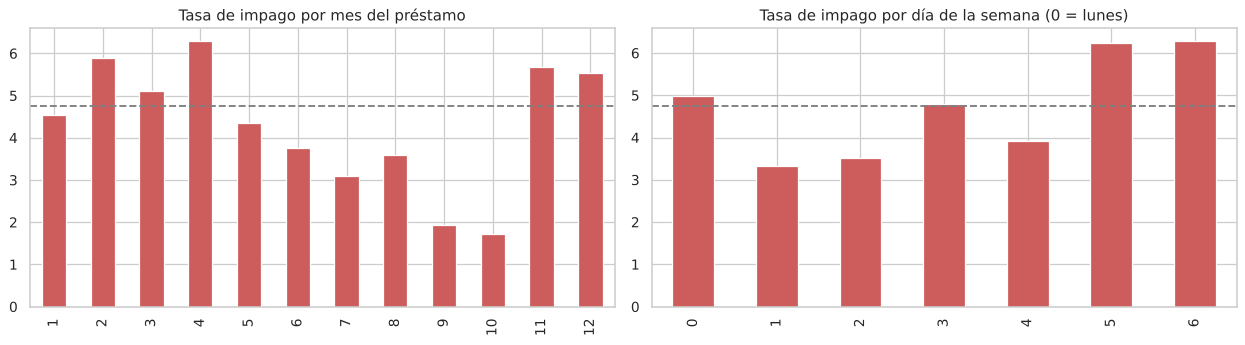

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tasa_impago_por_grupo(derivados, "mes_prestamo")[TASA].plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("Tasa de impago por mes del préstamo")
tasa_impago_por_grupo(derivados, "dia_semana_prestamo")[TASA].plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Tasa de impago por día de la semana (0 = lunes)")
for ax in axes:
    ax.axhline((1 - df[OBJETIVO].mean()) * 100, ls="--", color="grey")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Interpretación**

- `tiene_mora` es el derivado binario más fuerte: los 55 clientes con algún saldo en mora
  reportado tienen una tasa de impago del 36,4 %, frente al 4,6 % del resto.
- `huella_alta` (más consultas que el 75 % de los clientes) eleva la tasa de impago del 4,1 % al
  7,5 %, y `sin_info_ingresos_central`, del 4,4 % al 5,7 %. Son indicadores simples y conviene
  incluirlos.
- `sin_puntaje_central` (152 clientes) tiene una tasa del 7,2 %, aunque con pocos casos.
- `ratio_capital_salario` y `ratio_otros_prestamos_salario` muestran diferencias pequeñas pero
  significativas. Se recomienda conservarlos porque resumen información de negocio y reemplazan
  pares de variables muy correlacionadas.
- `ratio_salario_vs_central` es el ratio que más separa las clases: los clientes que no pagan
  declaran un salario mayor en relación con el ingreso que estima la central (mediana de 2,2
  frente a 1,8 veces). *Inferencia:* una sobredeclaración de ingresos es una señal de riesgo.
- `ratio_cuota_salario` no separa las clases (p = 0,46), en línea con lo visto para el salario.
- Los atributos de calendario muestran variaciones: los préstamos de fin de mes (5,5 % frente a
  4,5 %) y de fin de semana tienen tasas algo mayores, y los meses de septiembre y octubre, menores.
  Parte de esto refleja la evolución temporal vista en 5.4, así que se deben usar con cautela
  para no sobreajustar a la estacionalidad de un periodo corto (17 meses).

## 10. Conclusiones y siguientes pasos

**Calidad de datos**

1. El dataset tiene 10.763 créditos, 23 columnas y ninguna fila duplicada.
2. Hay nulos explícitos en 7 columnas, concentrados en los datos de ingresos de la central (27 %)
   y con un patrón conjunto que indica que dependen de la fuente.
3. Hay nulos implícitos y errores de carga: 150 edades centinela, 147 puntajes de central no
   válidos, 58 valores numéricos en `tendencia_ingresos` y salarios extremos o en cero.

**Hallazgos para el modelado**

1. La variable objetivo está muy desbalanceada (4,7 % de impagos), lo que condiciona las
   métricas y la estrategia de entrenamiento.
2. `puntaje` separa casi perfectamente las clases. Debe confirmarse que no se calcule después
   del pago antes de usarla; mientras tanto, se excluye.
3. Sin `puntaje`, las señales son débiles pero consistentes: puntaje de la central, huella de
   consulta, edad, ingreso estimado por la central, monto, plazo largo (en el producto 4), tipo
   laboral, tendencia de ingresos, mora previa y ausencia de información de la central.
4. Las variables monetarias son log-normales con atípicos extremos y deben transformarse.
5. Hay grupos de variables redundantes (capital-cuota, saldos, conteos de créditos).
6. La tasa de impago y el volumen cambian con el tiempo; hay que validar también de forma
   temporal y monitorear la deriva.

**Insumos para las etapas siguientes**

- Reglas de validación: sección 7 (`REGLAS_VALIDACION`).
- Transformaciones: sección 8.
- Atributos derivados: sección 9.

**Preguntas para negocio**

- ¿En qué momento se calcula `puntaje`?
- ¿Cuál es el rango oficial de `puntaje_datacredito` y qué significan 0, 7, -7 y los valores superiores a 950?
- ¿Qué significan las edades de 121 a 123 años y los salarios de cero o de miles de millones?
- ¿Por qué cae el volumen de créditos desde mediados de 2025?
- ¿Cuál es el catálogo vigente de `tipo_credito` (en particular, el código 68)?